## 1. Installation & Setup

In [ ]:
# Install Tinker SDK and dependencies
%pip install -q tinker transformers torch datasets numpy

In [ ]:
# 安装/更新 widgets 插件
%pip install -q -U ipywidgets jupyterlab_widgets

# 如果你是在本地 VS Code 或 Jupyter Lab 运行，建议安装完后重启一下内核 (Restart Kernel)

In [ ]:
# (Optional) Install the Tinker Cookbook for higher-level abstractions
!pip install -q git+https://github.com/thinking-machines-lab/tinker-cookbook.git

In [1]:
import os
from getpass import getpass

# Set your Tinker API key
if "TINKER_API_KEY" not in os.environ:
    os.environ["TINKER_API_KEY"] = getpass("Enter your Tinker API key: ")

# (Optional) HuggingFace token if the dataset is private/gated
if "HF_TOKEN" not in os.environ:
    os.environ["HF_TOKEN"] = getpass("Enter your HuggingFace token (or press Enter to skip): ")

In [1]:
import tinker
from tinker import types
import numpy as np
import json
import time

# Verify connection to Tinker
service_client = tinker.ServiceClient()
capabilities = service_client.get_server_capabilities()
print("Connected to Tinker! Available models:")
for m in capabilities.supported_models:
    if "Qwen3" in m.model_name:
        print(f"  - {m.model_name}")

Connected to Tinker! Available models:
  - Qwen/Qwen3-235B-A22B-Instruct-2507
  - Qwen/Qwen3-30B-A3B
  - Qwen/Qwen3-30B-A3B-Base
  - Qwen/Qwen3-30B-A3B-Instruct-2507
  - Qwen/Qwen3-32B
  - Qwen/Qwen3-4B-Instruct-2507
  - Qwen/Qwen3-8B
  - Qwen/Qwen3-8B-Base
  - Qwen/Qwen3-VL-235B-A22B-Instruct
  - Qwen/Qwen3-VL-30B-A3B-Instruct
  - Qwen/Qwen3.5-27B
  - Qwen/Qwen3.5-35B-A3B
  - Qwen/Qwen3.5-397B-A17B
  - Qwen/Qwen3.5-397B-A17B:peft:262144
  - Qwen/Qwen3.5-4B
  - Qwen/Qwen3.6-27B
  - Qwen/Qwen3.6-35B-A3B


## 2. Load and Explore the Dataset

We load the `Alan123/homo-lumo-grpo` dataset from HuggingFace. This dataset contains chemistry problems related to HOMO-LUMO gap predictions.

> **Note:** Adjust the column names below (`"prompt"`, `"answer"`, etc.) to match the actual schema of your dataset. Run the exploration cell first to see the column names.

In [2]:
#配置代理环境

import os
import socket

# 1. 设置你探测到的 IP 或 OrbStack 专用域名
# 如果 ip route 返回的是 192.168.1.5，就填 http://192.168.1.5:7897
proxy_host = "172.18.48.1" # 如果是纯原生 Linux
# proxy_host = "host.orb.internal" # 如果是 macOS OrbStack
# proxy_host = "172.xx.xx.xx" # 如果是 WSL2/Docker，填 ip route 出来的网关

proxy_url = f"http://{proxy_host}:7897"

# 2. 先做最简单的“端口探活”，不用发 HTTP 请求
def test_port(ip, port):
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.settimeout(2)
        return s.connect_ex((ip, port)) == 0

if test_port(proxy_host, 7897):
    print(f"✅ 成功发现代理服务：{proxy_url}")
    os.environ["http_proxy"] = proxy_url
    os.environ["https_proxy"] = proxy_url
    
    # 尝试加载数据
    from datasets import load_dataset
    try:
        # 这里建议先不传 token 试试，如果数据集是公开的
        dataset = load_dataset("Alan123/qa_dataset_with_qed_logp_mw_grpo")
        print("🚀 数据集加载成功！")
    except Exception as e:
        print(f"❌ 代理通了但下载失败: {e}")
else:
    print(f"❌ 依然无法连接到 {proxy_host}:7897。请确认 Clash 的 'Allow LAN' 已开启。")

✅ 成功发现代理服务：http://172.18.48.1:7897


🚀 数据集加载成功！


In [3]:
import os
import json
import time
from datasets import load_dataset, Dataset

# Keep original dataset directly. No four-step synthetic data generation.
print("Using original prompt/ground-truth dataset directly (no four-step synthesis).")

if "dataset" not in globals():
    dataset = load_dataset("Alan123/qa_dataset_with_qed_logp_mw_grpo")

if hasattr(dataset, "keys") and "train" in dataset:
    train_split = dataset["train"]
else:
    train_split = dataset

subset = train_split.select(range(min(10, len(train_split))))
print(f"Loaded train split size: {len(train_split)}")
print(f"Debug subset size: {len(subset)}")

Using original prompt/ground-truth dataset directly (no four-step synthesis).
Loaded train split size: 163415
Debug subset size: 10


In [4]:
# ============================================================================
# IMPORTANT: Update these column names based on your dataset's actual schema!
# ============================================================================
# After running the cell above, check the column names and update accordingly.
#
# Common patterns for GRPO chemistry datasets:
#   - "prompt" or "question" or "smiles" or "input" -> the question/molecule
#   - "answer" or "target" or "homo_lumo_gap" or "label" -> the ground truth
#   - "messages" -> pre-formatted chat messages
#
# We provide TWO paths below:
#   Path A: Dataset has "prompt" and "answer" columns
#   Path B: Dataset has pre-formatted "messages" column
#
# Uncomment the path that matches your dataset.

# --- Path A: prompt + answer columns ---
PROMPT_COL = "input"       # <-- UPDATE to your prompt column name
ANSWER_COL = "output"       # <-- UPDATE to your answer column name
DATA_SPLIT = "train"        # <-- UPDATE if needed

# --- Path B: pre-formatted messages ---
# MESSAGES_COL = "messages"  # <-- Uncomment if your dataset uses messages format

raw_data = dataset[DATA_SPLIT]
# raw_data = raw_data_origin[:10000]
print(raw_data)
print(f"Loaded {len(raw_data)} training examples")

Dataset({
    features: ['input', 'output'],
    num_rows: 163415
})
Loaded 163415 training examples


## 3. Configure the Model and Renderer

We'll use **Qwen3-8B** (a good balance of cost and capability). For larger-scale experiments, you can switch to `Qwen/Qwen3-30B-A3B` (MoE, very cost-effective) or `Qwen/Qwen3-32B` (dense).

Tinker uses a **Renderer** to convert chat messages into token sequences with proper special tokens and loss weights.

In [5]:
# Choose your base model
# Options: "Qwen/Qwen3-8B", "Qwen/Qwen3-30B-A3B", "Qwen/Qwen3-32B", etc.
BASE_MODEL = "Qwen/Qwen3-8B"

# LoRA rank: higher = more capacity but costs more. 32 is a good default.
LORA_RANK = 32

print(f"Base model: {BASE_MODEL}")
print(f"LoRA rank: {LORA_RANK}")

Base model: Qwen/Qwen3-8B
LoRA rank: 32


In [6]:
# Set up the renderer for Qwen3 chat format
# The renderer handles special tokens (<|im_start|>, <|im_end|>, etc.)
# and produces proper loss masks for training.

from tinker_cookbook import renderers, tokenizer_utils

tokenizer = tokenizer_utils.get_tokenizer(BASE_MODEL)
renderer = renderers.get_renderer('qwen3', tokenizer)

print(f"Tokenizer vocab size: {tokenizer.vocab_size}")
print(f"Stop sequences: {renderer.get_stop_sequences()}")

Tokenizer vocab size: 151643
Stop sequences: [151645]


## 4. Data Preparation Helpers

We need functions to convert our dataset into the format Tinker expects:
- **For SFT:** `types.Datum` with `model_input` and `loss_fn_inputs` (weights and target_tokens)
- **For GRPO:** Chat messages that can be rendered into prompts for sampling

In [7]:
# System prompt for chemistry optimization tasks
SYSTEM_PROMPT = (
    "You are a helpful chemistry assistant. "
    "You need to modify the input molecule to match specific property constraints."
)


def make_messages(example):
    """
    Convert a raw dataset example into a list of chat messages.
    Update this function based on your dataset's column schema.
    """
    # Path A: prompt + answer columns
    prompt_text = example[PROMPT_COL]
    answer_text = str(example[ANSWER_COL])

    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": prompt_text},
        {"role": "assistant", "content": answer_text},
    ]
    return messages


    # Path B: pre-formatted messages
    # return example[MESSAGES_COL]


def make_prompt_messages(example, system_prompt=SYSTEM_PROMPT):
    """
    Create the prompt-only messages (no assistant response) for RL sampling.
    """
    prompt_text = example[PROMPT_COL]
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": prompt_text},
    ]
    return messages

## 5. Stage 1: Supervised Fine-Tuning (SFT)

SFT teaches the model the basic format and chemistry knowledge. We use the `cross_entropy` loss function, which trains the model to predict the next token for the assistant's response.

**Tinker's training loop:**
1. Prepare a batch of `Datum` objects
2. Call `forward_backward()` to compute gradients
3. Call `optim_step()` to update the LoRA weights
4. Repeat

## 6. Plot SFT Training Curves

---

## 7. Stage 2: Reinforcement Learning

Now we switch to **GRPO-style RL training** to improve the model's accuracy using a reward signal.

**How GRPO works with Tinker:**
1. For each prompt, **sample G completions** from the current model
2. **Score** each completion with a reward function
3. Compute **group-normalized advantages** (subtract mean, divide by std within each group)
4. Use the `ppo` (or `importance_sampling`) loss to update the policy

Tinker's built-in `ppo` loss handles the clipped surrogate objective. The GRPO-specific part (group normalization of advantages) is done on the client side.

---

## 关于qed logp mw的rewardFunc

In [8]:
import re
from rdkit import Chem
from rdkit import DataStructs
from rdkit.Chem import QED
from rdkit.Chem import Descriptors
from rdkit.Chem import Crippen
from rdkit.Chem import rdFingerprintGenerator
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")
from typing import Dict, List, Tuple
from collections import defaultdict, deque


def _canonical_smiles(smiles_text: str) -> str | None:
    """Return canonical SMILES, or None if parsing fails."""
    if not smiles_text:
        return None
    mol = Chem.MolFromSmiles(smiles_text)
    if mol is None:
        return None
    return Chem.MolToSmiles(mol)


def strict_format_reward(completions: List[str], **kwargs) -> List[float]:
    """
    +1.0 if the completion matches:
      'Replace ... with ... to form <SMILES>...</SMILES>.'   OR
      'Add ... to form <SMILES>...</SMILES>.'                OR
      'Remove ... to form <SMILES>...</SMILES>.'
    else -4.0
    """
    pat = re.compile(
        r"^(Replace|Add|Remove)\s+(.+?)(?:\s+with\s+(.+?))?\s+to\s+form\s+<SMILES>(.+)</SMILES>\.$",
        re.DOTALL,
    )
    rewards = []
    for text in completions:
        m = pat.fullmatch(text.strip())
        rewards.append(1.0 if m else -4.0)
    return rewards


REPETITION_WINDOW_ITERATIONS = 2
REPETITION_PENALTY_STEP = 0.1
REPETITION_PENALTY_FLOOR = -0.4
_repetition_iteration_window = deque()
_repetition_history_counts = defaultdict(int)


def reset_repetition_window() -> None:
    global _repetition_iteration_window, _repetition_history_counts
    _repetition_iteration_window = deque()
    _repetition_history_counts = defaultdict(int)


def configure_repetition_window(
    window_size_iterations: int = 2,
    penalty_step: float = 0.1,
    penalty_floor: float = -0.4,
) -> dict[str, float]:
    if window_size_iterations < 1:
        raise ValueError("window_size_iterations must be >= 1")
    if penalty_step < 0.0:
        raise ValueError("penalty_step must be >= 0")
    if penalty_floor > 0.0:
        raise ValueError("penalty_floor must be <= 0")

    globals()["REPETITION_WINDOW_ITERATIONS"] = int(window_size_iterations)
    globals()["REPETITION_PENALTY_STEP"] = float(penalty_step)
    globals()["REPETITION_PENALTY_FLOOR"] = float(penalty_floor)
    reset_repetition_window()
    return {
        "window_size_iterations": int(REPETITION_WINDOW_ITERATIONS),
        "penalty_step": float(REPETITION_PENALTY_STEP),
        "penalty_floor": float(REPETITION_PENALTY_FLOOR),
    }


def _current_repetition_history_counts() -> dict[str, int]:
    return dict(_repetition_history_counts)


def _extract_final_canonical_smiles_for_repetition(text: str) -> str | None:
    m = re.search(r"<SMILES>(.*?)</SMILES>", text or "")
    if not m:
        return None
    return _canonical_smiles(m.group(1).strip())


def collect_repetition_smiles(completions: List[str], **kwargs) -> List[str]:
    collected = []
    for text in completions:
        can = _extract_final_canonical_smiles_for_repetition(text)
        if can:
            collected.append(can)
    return collected


def update_repetition_history(smiles_list: List[str]) -> dict[str, int]:
    global _repetition_iteration_window, _repetition_history_counts

    bucket = [smi for smi in smiles_list if smi]
    _repetition_iteration_window.append(bucket)
    while len(_repetition_iteration_window) > REPETITION_WINDOW_ITERATIONS:
        _repetition_iteration_window.popleft()

    new_counts = defaultdict(int)
    for hist_bucket in _repetition_iteration_window:
        for smi in hist_bucket:
            new_counts[smi] += 1
    _repetition_history_counts = new_counts
    return dict(_repetition_history_counts)


def repetition_penalty_reward(
    completions: List[str],
    history_counts: Dict[str, int] | None = None,
    **kwargs,
) -> List[float]:
    """Penalize short-term duplicate final canonical SMILES only."""
    counts = history_counts if history_counts is not None else _current_repetition_history_counts()
    rewards = []
    for text in completions:
        can = _extract_final_canonical_smiles_for_repetition(text)
        if not can:
            rewards.append(0.0)
            continue

        count = int(counts.get(can, 0))
        penalty = max(-REPETITION_PENALTY_STEP * count, REPETITION_PENALTY_FLOOR)
        rewards.append(float(penalty))
    return rewards


configure_repetition_window()


def multi_property_reward(completions: List[str], **kwargs) -> List[float]:
    """
    Reward in [-2, 1], derived from direction-aware normalized error.

    We cap total error before mapping to reward to avoid saturation near -4,
    which keeps property signal informative for RL updates.
    """
    prompts: List[str] = kwargs["prompts"]
    out = []

    # Cap controls floor: reward = 1 - clip(total_err, 0, cap) -> [1-cap, 1]
    err_cap = 3.0

    for comp, prompt in zip(completions, prompts):
        in_m = re.search(r"<SMILES>(.*?)</SMILES>", prompt)
        out_m = re.search(r"<SMILES>(.*?)</SMILES>", comp)
        qed_m = re.search(r"<QED>(-?\d+\.\d+)</QED>\s*(higher|lower)", prompt)
        logp_m = re.search(r"<LogP>(-?\d+\.\d+)</LogP>\s*(higher|lower)", prompt)
        mw_m = re.search(r"<MW>(-?\d+\.\d+)</MW>\s*(higher|lower)", prompt)

        if not (in_m and out_m and qed_m and logp_m and mw_m):
            out.append(-4.0)
            continue

        s_in, s_out = in_m.group(1), out_m.group(1)
        m_in, m_out = Chem.MolFromSmiles(s_in), Chem.MolFromSmiles(s_out)
        if not (m_in and m_out):
            out.append(-4.0)
            continue

        qed_in = QED.qed(m_in)
        logp_in = Crippen.MolLogP(m_in)
        mw_in = Descriptors.ExactMolWt(m_in)

        qed_out = QED.qed(m_out)
        logp_out = Crippen.MolLogP(m_out)
        mw_out = Descriptors.ExactMolWt(m_out)

        def _parse(m, base):
            delta = float(m.group(1))
            direction = 1 if m.group(2) == "higher" else -1
            return base + direction * delta, direction

        qed_t, d_qed = _parse(qed_m, qed_in)
        logp_t, d_logp = _parse(logp_m, logp_in)
        mw_t, d_mw = _parse(mw_m, mw_in)

        qed_t = max(0.01, min(0.99, qed_t))

        qed_err = abs(qed_out - qed_t) / 0.5
        logp_err = abs(logp_out - logp_t) / 3.0
        mw_err = abs(mw_out - mw_t) / 50.0

        dir_pen_qed = 4 if (qed_out - qed_in) * d_qed < 0 else 1
        dir_pen_logp = 4 if (logp_out - logp_in) * d_logp < 0 else 1
        dir_pen_mw = 4 if (mw_out - mw_in) * d_mw < 0 else 1

        total_err = (
            qed_err * dir_pen_qed
            + logp_err * dir_pen_logp
            + mw_err * dir_pen_mw
        )

        bounded_err = min(max(total_err, 0.0), err_cap)
        reward = 1.0 - bounded_err
        out.append(reward)
    return out


In [9]:
"""
Reward utilities for non-four-step training.

This version removes ANALYZE/PLAN/EDIT/VERIFY step parsing and scores
the model directly from completion text, prompt, and ground truth.
"""

RDLogger.DisableLog("rdApp.*")


def extract_smiles(text: str | None) -> str | None:
    """Extract SMILES inside <SMILES>...</SMILES>."""
    if not text:
        return None
    m = re.search(r"<SMILES>(.*?)</SMILES>", text)
    return m.group(1).strip() if m else None


def _normalize_completion_text(text: str) -> str:
    """Drop think blocks and surrounding spaces."""
    if not text:
        return ""
    clean = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL)
    return clean.replace("<|im_end|>", "").strip()

_MORGAN_GEN = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
def compute_similarity_reward(mol_pred, mol_target) -> float:
    """Tanimoto similarity on Morgan fingerprints."""
    if mol_pred is None or mol_target is None:
        return 0.0
    fp_pred = _MORGAN_GEN.GetFingerprint(mol_pred)
    fp_target = _MORGAN_GEN.GetFingerprint(mol_target)
    return float(DataStructs.TanimotoSimilarity(fp_pred, fp_target))


SOFT_FORMAT_FLOOR = -4.0
SOFT_PROPERTY_FLOOR = -2.5
TOTAL_REWARD_FLOOR = -2.0

# Reward decomposition for per-iteration diagnostics.
BASE_REWARD_WEIGHTS = {
    "property": 0.70,
    "format": 0.20,
    "similarity": 0.20,
    "repetition": 0.05,
}
DEFAULT_BASE_REWARD_WEIGHTS = dict(BASE_REWARD_WEIGHTS)


def set_base_reward_weights(weights: dict[str, float] | None = None) -> dict[str, float]:
    source = DEFAULT_BASE_REWARD_WEIGHTS if weights is None else weights
    BASE_REWARD_WEIGHTS.clear()
    BASE_REWARD_WEIGHTS.update({key: float(value) for key, value in source.items()})
    return dict(BASE_REWARD_WEIGHTS)


def resolve_reward_weights(use_repetition_reward: bool = False) -> dict[str, float]:
    weights = dict(BASE_REWARD_WEIGHTS)
    if not use_repetition_reward:
        weights["repetition"] = 0.0
    return weights


def compute_reward_components(
    completion_text: str,
    prompt_text: str,
    ground_truth: str,
    reward_weights: dict[str, float] | None = None,
    repetition_history_counts: dict[str, int] | None = None,
) -> dict:
    """
    Return decomposed reward terms for diagnostics and training.

    Keys:
      strict, property, similarity, repetition, weighted_total, total,
      has_smiles, valid_smiles
    """
    reward_weights = reward_weights or resolve_reward_weights(False)
    if repetition_history_counts is None:
        repetition_history_counts = _current_repetition_history_counts()
    text = _normalize_completion_text(completion_text)
    pred_smiles = extract_smiles(text)

    if not pred_smiles:
        return {
            "strict": -4.0,
            "property": -4.0,
            "similarity": 0.0,
            "repetition": 0.0,
            "weighted_total": -4.0,
            "total": -4.0,
            "has_smiles": False,
            "valid_smiles": False,
        }

    mol_pred = Chem.MolFromSmiles(pred_smiles)
    if mol_pred is None:
        return {
            "strict": -4.0,
            "property": -4.0,
            "similarity": 0.0,
            "repetition": 0.0,
            "weighted_total": -4.0,
            "total": -4.0,
            "has_smiles": True,
            "valid_smiles": False,
        }

    target_smiles = extract_smiles(ground_truth) or str(ground_truth).strip()
    mol_target = Chem.MolFromSmiles(target_smiles)

    # Soft floors prevent a single malformed output from dominating policy updates.
    strict_score = max(strict_format_reward([text])[0], SOFT_FORMAT_FLOOR)
    property_score = max(
        multi_property_reward([text], prompts=[prompt_text])[0],
        SOFT_PROPERTY_FLOOR,
    )
    similarity_score = compute_similarity_reward(mol_pred, mol_target)
    repetition_score = repetition_penalty_reward([text], history_counts=repetition_history_counts)[0]

    weighted_total = (
        reward_weights["property"] * property_score
        + reward_weights["format"] * strict_score
        + reward_weights["similarity"] * similarity_score
        + reward_weights["repetition"] * repetition_score
    )
    total = float(max(weighted_total, TOTAL_REWARD_FLOOR))

    return {
        "strict": float(strict_score),
        "property": float(property_score),
        "similarity": float(similarity_score),
        "repetition": float(repetition_score),
        "weighted_total": float(weighted_total),
        "effective_repetition_weight": float(reward_weights.get("repetition", 0.0)),
        "total": total,
        "has_smiles": True,
        "valid_smiles": True,
    }


def compute_reward(
    completion_text: str,
    prompt_text: str,
    ground_truth: str,
    reward_weights: dict[str, float] | None = None,
    repetition_history_counts: dict[str, int] | None = None,
) -> float:
    """Backward-compatible scalar reward interface."""
    return float(
        compute_reward_components(
            completion_text,
            prompt_text,
            ground_truth,
            reward_weights=reward_weights,
            repetition_history_counts=repetition_history_counts,
        )["total"]
    )


# Baseline v2

In [10]:
# Baseline-v2 reward: active replacement for the clipped property reward above.
# Core change: score target-error improvement instead of clipping most bad samples to -2.

BASELINE_V2_PROPERTY_DELTA_CLIP = 5.0
BASELINE_V2_DIRECTION_WEIGHT = 0.2

BASE_REWARD_WEIGHTS = {
    "property": 1.0,
    "format": 0.0,       # format is a gate in v2, not an additive reward
    "similarity": 0.10,
    "repetition": 0.05,
}
DEFAULT_BASE_REWARD_WEIGHTS = dict(BASE_REWARD_WEIGHTS)


def _parse_property_targets(prompt_text: str, mol_in):
    """Return absolute QED/LogP/MW targets and requested directions."""
    specs = {}
    for prop in ("QED", "LogP", "MW"):
        m = re.search(rf"<{prop}>(-?\d*\.?\d+)</{prop}>\s*(higher|lower)", prompt_text)
        if not m:
            return None
        delta = float(m.group(1))
        direction = 1 if m.group(2) == "higher" else -1
        specs[prop.lower()] = (delta, direction)

    input_props = {
        "qed": float(QED.qed(mol_in)),
        "logp": float(Crippen.MolLogP(mol_in)),
        "mw": float(Descriptors.ExactMolWt(mol_in)),
    }
    qed_delta, d_qed = specs["qed"]
    logp_delta, d_logp = specs["logp"]
    mw_delta, d_mw = specs["mw"]

    target = {
        "qed": max(0.01, min(0.99, input_props["qed"] + d_qed * qed_delta)),
        "logp": input_props["logp"] + d_logp * logp_delta,
        "mw": input_props["mw"] + d_mw * mw_delta,
    }
    directions = {"qed": d_qed, "logp": d_logp, "mw": d_mw}
    return target, directions, input_props


def _property_values(mol) -> dict[str, float]:
    return {
        "qed": float(QED.qed(mol)),
        "logp": float(Crippen.MolLogP(mol)),
        "mw": float(Descriptors.ExactMolWt(mol)),
    }


def property_error(mol, target: dict[str, float]) -> tuple[float, dict[str, float]]:
    props = _property_values(mol)
    parts = {
        "qed_err": abs(props["qed"] - target["qed"]) / 0.5,
        "logp_err": abs(props["logp"] - target["logp"]) / 3.0,
        "mw_err": abs(props["mw"] - target["mw"]) / 50.0,
    }
    return float(parts["qed_err"] + parts["logp_err"] + parts["mw_err"]), parts


NTE_LOGP_SCALE = 10.0
NTE_MW_SCALE = 700.0


def normalized_total_error(qed_error: float, logp_error: float, mw_error: float) -> float:
    """NTE/enorm = |dQED| + |dLogP|/10 + |dMW|/700."""
    return float(abs(qed_error) + abs(logp_error) / NTE_LOGP_SCALE + abs(mw_error) / NTE_MW_SCALE)


def compute_initial_target_nte_details(final_smiles: str | None, initial_prompt_text: str) -> dict:
    """Compare the final valid molecule against the original absolute target."""
    details = {
        "nte": None,
        "qed_abs_error": None,
        "logp_abs_error": None,
        "mw_abs_error": None,
        "nte_failure": None,
    }
    if not final_smiles:
        details["nte_failure"] = "missing_final_smiles"
        return details

    initial_smiles = extract_smiles(initial_prompt_text)
    if not initial_smiles:
        details["nte_failure"] = "missing_initial_smiles"
        return details

    mol_initial = Chem.MolFromSmiles(initial_smiles)
    mol_final = Chem.MolFromSmiles(final_smiles)
    if mol_initial is None or mol_final is None:
        details["nte_failure"] = "invalid_smiles"
        return details

    parsed = _parse_property_targets(initial_prompt_text, mol_initial)
    if parsed is None:
        details["nte_failure"] = "target_parse_failed"
        return details

    target, _directions, input_props = parsed
    final_props = _property_values(mol_final)
    delta_qed = float(final_props["qed"] - target["qed"])
    delta_logp = float(final_props["logp"] - target["logp"])
    delta_mw = float(final_props["mw"] - target["mw"])
    nte = normalized_total_error(delta_qed, delta_logp, delta_mw)

    details.update(
        {
            "nte": float(nte),
            "qed_abs_error": float(abs(delta_qed)),
            "logp_abs_error": float(abs(delta_logp)),
            "mw_abs_error": float(abs(delta_mw)),
            "delta_qed": delta_qed,
            "delta_logp": delta_logp,
            "delta_mw": delta_mw,
            "qed_initial": float(input_props["qed"]),
            "logp_initial": float(input_props["logp"]),
            "mw_initial": float(input_props["mw"]),
            "qed_target_initial": float(target["qed"]),
            "logp_target_initial": float(target["logp"]),
            "mw_target_initial": float(target["mw"]),
            "qed_final": float(final_props["qed"]),
            "logp_final": float(final_props["logp"]),
            "mw_final": float(final_props["mw"]),
            "final_smiles": Chem.MolToSmiles(mol_final, canonical=True),
            "nte_failure": None,
        }
    )
    return details


def compute_property_reward_details(completion_text: str, prompt_text: str) -> dict:
    text = _normalize_completion_text(completion_text)
    in_smiles = extract_smiles(prompt_text)
    out_smiles = extract_smiles(text)
    details = {
        "old_err": None,
        "new_err": None,
        "property_delta_raw": 0.0,
        "property_delta": 0.0,
        "direction_score": 0.0,
        "property_reward": 0.0,
        "property_failure": None,
    }
    if not in_smiles or not out_smiles:
        details["property_failure"] = "missing_smiles"
        return details

    mol_in = Chem.MolFromSmiles(in_smiles)
    mol_out = Chem.MolFromSmiles(out_smiles)
    if mol_in is None or mol_out is None:
        details["property_failure"] = "invalid_smiles"
        return details

    parsed = _parse_property_targets(prompt_text, mol_in)
    if parsed is None:
        details["property_failure"] = "target_parse_failed"
        return details
    target, directions, input_props = parsed

    old_err, old_parts = property_error(mol_in, target)
    new_err, new_parts = property_error(mol_out, target)
    property_delta_raw = old_err - new_err
    property_delta = max(
        min(property_delta_raw, BASELINE_V2_PROPERTY_DELTA_CLIP),
        -BASELINE_V2_PROPERTY_DELTA_CLIP,
    )

    output_props = _property_values(mol_out)
    direction_terms = []
    dir_details = {}
    for prop in ("qed", "logp", "mw"):
        term = 1.0 if (output_props[prop] - input_props[prop]) * directions[prop] >= 0 else -1.0
        direction_terms.append(term)
        dir_details[f"dir_score_{prop}"] = term
    direction_score = float(sum(direction_terms) / 3.0)
    property_reward = float(property_delta + BASELINE_V2_DIRECTION_WEIGHT * direction_score)

    details.update(
        {
            "old_err": float(old_err),
            "new_err": float(new_err),
            "old_qed_err": float(old_parts["qed_err"]),
            "old_logp_err": float(old_parts["logp_err"]),
            "old_mw_err": float(old_parts["mw_err"]),
            "qed_err": float(new_parts["qed_err"]),
            "logp_err": float(new_parts["logp_err"]),
            "mw_err": float(new_parts["mw_err"]),
            "property_delta_raw": float(property_delta_raw),
            "property_delta": float(property_delta),
            "direction_score": direction_score,
            "property_reward": property_reward,
            "qed_target": float(target["qed"]),
            "logp_target": float(target["logp"]),
            "mw_target": float(target["mw"]),
            "qed_in": float(input_props["qed"]),
            "logp_in": float(input_props["logp"]),
            "mw_in": float(input_props["mw"]),
            "qed_out": float(output_props["qed"]),
            "logp_out": float(output_props["logp"]),
            "mw_out": float(output_props["mw"]),
            "property_failure": None,
        }
    )
    details.update(dir_details)
    return details


def multi_property_reward(completions: List[str], **kwargs) -> List[float]:
    prompts: List[str] = kwargs["prompts"]
    return [
        float(compute_property_reward_details(comp, prompt)["property_reward"])
        for comp, prompt in zip(completions, prompts)
    ]


def compute_reward_components(
    completion_text: str,
    prompt_text: str,
    ground_truth: str,
    reward_weights: dict[str, float] | None = None,
    repetition_history_counts: dict[str, int] | None = None,
) -> dict:
    reward_weights = reward_weights or resolve_reward_weights(False)
    if repetition_history_counts is None:
        repetition_history_counts = _current_repetition_history_counts()

    text = _normalize_completion_text(completion_text)
    pred_smiles = extract_smiles(text)
    mol_pred = Chem.MolFromSmiles(pred_smiles) if pred_smiles else None
    strict_score = strict_format_reward([text])[0]
    valid_format = strict_score > 0.0 and mol_pred is not None
    format_gate = 1.0 if valid_format else 0.0

    target_smiles = extract_smiles(ground_truth) or str(ground_truth).strip()
    mol_target = Chem.MolFromSmiles(target_smiles) if target_smiles else None
    similarity_score = compute_similarity_reward(mol_pred, mol_target)
    repetition_score = repetition_penalty_reward([text], history_counts=repetition_history_counts)[0]
    prop_details = compute_property_reward_details(text, prompt_text)
    property_score = float(prop_details["property_reward"])

    weighted_total = (
        reward_weights.get("property", 1.0) * property_score
        + reward_weights.get("similarity", 0.1) * similarity_score
        + reward_weights.get("repetition", 0.0) * repetition_score
    )
    total = float(format_gate * weighted_total)

    out = {
        "strict": float(strict_score),
        "format_gate": float(format_gate),
        "property": property_score,
        "similarity": float(similarity_score),
        "repetition": float(repetition_score),
        "weighted_total": float(weighted_total),
        "effective_repetition_weight": float(reward_weights.get("repetition", 0.0)),
        "total": total,
        "has_smiles": bool(pred_smiles),
        "valid_smiles": mol_pred is not None,
        "valid_format": bool(valid_format),
    }
    out.update(prop_details)
    return out


def compute_reward(
    completion_text: str,
    prompt_text: str,
    ground_truth: str,
    reward_weights: dict[str, float] | None = None,
    repetition_history_counts: dict[str, int] | None = None,
) -> float:
    return float(
        compute_reward_components(
            completion_text,
            prompt_text,
            ground_truth,
            reward_weights=reward_weights,
            repetition_history_counts=repetition_history_counts,
        )["total"]
    )


print("Baseline-v2 reward active: property_delta + 0.2*direction_score, format as gate, no hard property floor.")


Baseline-v2 reward active: property_delta + 0.2*direction_score, format as gate, no hard property floor.


In [11]:
# Group-normalized advantages used by GRPO.
def compute_group_advantages(rewards: list[float]) -> list[float]:
    """
    GRPO-style group normalization: (r - mean) / std.
    Return zeros when std is near zero to avoid NaN.
    """
    arr = np.array(rewards, dtype=np.float64)
    std = arr.std()
    if std < 1e-8:
        return [0.0] * len(rewards)
    return ((arr - arr.mean()) / std).tolist()

In [12]:
# Shared helpers for multi-turn RL.

import re
import numpy as np
from typing import Optional

import tinker
from tinker import types
from rdkit import Chem, RDLogger
from rdkit.Chem import QED, Descriptors, Crippen

# Per-property tolerance for deciding whether a target is truly met.
TARGET_TOLERANCE = {
    "QED": 0.02,
    "LogP": 0.20,
    "MW": 5.0,
}


def _mol_from_prompt(prompt_text: str) -> Optional[Chem.Mol]:
    """Extract the input molecule from prompt <SMILES> tag."""
    m = re.search(r"<SMILES>(.*?)</SMILES>", prompt_text)
    if not m:
        return None
    return Chem.MolFromSmiles(m.group(1))


def _target_progress_lines(mol_in: Chem.Mol, mol_out: Chem.Mol, prompt_text: str) -> tuple[list[str], list[str]]:
    """
    Build per-property target progress lines.

    Returns:
      misses: properties that have not met their target by tolerance
      lines: concise human-readable lines with base/current/target and gap
    """
    prop_specs = [
        ("QED", QED.qed, "{:.3f}"),
        ("LogP", Crippen.MolLogP, "{:.3f}"),
        ("MW", Descriptors.ExactMolWt, "{:.3f}"),
    ]

    misses = []
    lines = []

    for prop, fn, fmt in prop_specs:
        m = re.search(rf"<{prop}>(-?\d*\.?\d+)</{prop}>\s*(higher|lower)", prompt_text)
        if not m:
            continue

        delta = float(m.group(1))
        direction = m.group(2).lower()

        base_val = float(fn(mol_in))
        current_val = float(fn(mol_out))
        sign = 1.0 if direction == "higher" else -1.0
        target_val = base_val + sign * delta

        if prop == "QED":
            target_val = max(0.01, min(0.99, target_val))

        # signed_need > 0: still short in required direction; <= 0: reached/passed direction.
        if direction == "higher":
            signed_need = target_val - current_val
            action = "increase"
        else:
            signed_need = current_val - target_val
            action = "decrease"

        still_needed = abs(signed_need)
        tol = TARGET_TOLERANCE.get(prop, 0.0)
        # direction_met means whether current change follows required direction from base.
        # It is independent from whether target tolerance has been reached.
        eps = 1e-12
        if direction == "higher":
            direction_met = (current_val - base_val) >= -eps
        else:
            direction_met = (base_val - current_val) >= -eps
        met = still_needed <= tol

        if signed_need > 0:
            progress_desc = f"need {fmt.format(still_needed)} more {action}"
        elif signed_need < 0:
            progress_desc = f"overshot by {fmt.format(still_needed)} in {action} direction"
        else:
            progress_desc = "exactly on target"

        if not met:
            misses.append(prop)

        lines.append(
            f"{prop}: base={fmt.format(base_val)}, current={fmt.format(current_val)}, "
            f"target={fmt.format(target_val)} ({direction} by {delta:.3f}), "
            f"still_needed={fmt.format(still_needed)} ({progress_desc}), "
            f"tol={fmt.format(tol)}, direction_met={direction_met}, met={met}"
        )

    return misses, lines


def _run_env(completion_text: str, prompt_text: str) -> tuple[str, Optional[Chem.Mol], bool]:
    """
    Environment step for multi-turn RL.

    prompt_text should be the CURRENT turn prompt, so base values are computed
    against the current molecule rather than always the initial molecule.
    """
    text = _normalize_completion_text(completion_text)
    pred_smiles = extract_smiles(text)
    if not pred_smiles:
        return "Your output did not contain a valid <SMILES>...</SMILES> block. Please revise.", None, False

    mol = Chem.MolFromSmiles(pred_smiles)
    if mol is None:
        return "The SMILES you provided is chemically invalid. Please revise.", None, False

    qed_val = QED.qed(mol)
    logp_val = Crippen.MolLogP(mol)
    mw_val = Descriptors.ExactMolWt(mol)

    mol_in = _mol_from_prompt(prompt_text)
    if mol_in is None:
        feedback = (
            f"Environment feedback: QED={qed_val:.3f}, LogP={logp_val:.2f}, MW={mw_val:.1f}. "
            "Input molecule is missing/invalid in prompt, so target gap is unavailable."
        )
        return feedback, mol, False

    misses, progress_lines = _target_progress_lines(mol_in, mol, prompt_text)
    all_met = len(progress_lines) > 0 and len(misses) == 0

    if progress_lines:
        progress_block = "\n- " + "\n- ".join(progress_lines)
    else:
        progress_block = "\n- No parseable target tags (<QED>/<LogP>/<MW>) found in prompt."

    if all_met:
        summary = "All targets met within tolerance. Keep output concise and chemically valid."
    else:
        unmet = ", ".join(misses) if misses else "unknown"
        summary = f"Targets not met (by target gap tolerance): {unmet}. Please refine toward target values."

    feedback = (
        f"Environment feedback: QED={qed_val:.3f}, LogP={logp_val:.2f}, MW={mw_val:.1f}."
        f"\nTarget progress:{progress_block}"
        f"\n{summary}"
    )
    return feedback, mol, all_met

In [13]:
# RL prompt: single action output only (no four-step chain-of-thought).
SYSTEM_PROMPT_RL = """
You are a helpful chemistry assistant for multi-turn molecule optimization.

Rules:
1) Output exactly one edit action sentence in one of these formats:
   - Replace <old_fragment> with <new_fragment> to form <SMILES>new_smiles_here</SMILES>.
   - Add <fragment> to form <SMILES>new_smiles_here</SMILES>.
   - Remove <fragment> to form <SMILES>new_smiles_here</SMILES>.
2) Do not output analysis/plan/verification/think blocks.
3) In turn >= 2, if the user provides a 'Current candidate molecule' SMILES,
   you must edit that candidate molecule, not the original input molecule.
"""

In [14]:
# ══════════════════════════════════════════════════════════════════════════════
#  修复5：Mode B 的组归一化 + EMA baseline
#
#  设计思路：
#    两个机制各司其职，解决不同层面的问题：
#
#    ① 组归一化（intra-prompt）
#       对同一 prompt 采 K 条轨迹，计算每条轨迹的折扣回报 G_k，
#       再做 (G_k - mean) / std 归一化。
#       作用：告诉模型"在同一起点下，哪种推理路径更优"。
#       这是 GRPO 的核心信号，Mode B 必须保留。
#
#    ② EMA baseline（inter-prompt）
#       维护一个跨 prompt、跨 iteration 的滑动平均 baseline。
#       在组归一化之后再减去 baseline（可选，作为二次校正）。
#       作用：防止某些 prompt 天然容易（reward 整体高）导致
#       advantage 尺度膨胀，稳定不同 prompt 之间的梯度大小。
#
#    两者的关系：
#      组归一化是"排名"，EMA 是"定零点"。
#      单独用 EMA（原始建议）：有零点但没有排名 → 信号弱。
#      只用组归一化：排名准确但跨 prompt 尺度不齐 → 梯度方差大。
#      两者结合：既有排名又有稳定尺度 → 最优。
#
#    关于 K 的选择：
#      Mode A：K=4~8（每条只需 1 次采样）
#      Mode B：K=2~3（每条需要 max_turns 次采样，成本是 Mode A 的 max_turns 倍）
#      K=1 时退化为普通 PG，组归一化失效，不建议使用。
# ══════════════════════════════════════════════════════════════════════════════
 
class EMABaseline:
    """
    指数移动平均 baseline，用于跨 prompt 稳定 advantage 的绝对尺度。
 
    update(G) 先返回当前 baseline 再更新，使得当前 batch 使用
    "历史经验"而非"本轮数据"作为参考，避免自举偏差。
    """
    def __init__(self, alpha: float = 0.05, init: float = 0.0):
        self.alpha   = alpha
        self.value   = init
        self._warmed = False  # 前几个样本用来热身，不参与训练
 
    def update_and_get(self, G: float) -> float:
        """返回当前 baseline，然后更新。"""
        current = self.value
        if not self._warmed:
            # 第一个样本直接初始化，避免初始 baseline=0 造成偏差
            self.value   = G
            self._warmed = True
        else:
            self.value = (1 - self.alpha) * self.value + self.alpha * G
        return current

In [15]:
# Multi-turn RL with environment feedback (no four-step parsing).
def run_mode_b(
    example: dict,
    renderer,
    sampling_client,
    tokenizer,
    ema_baseline: EMABaseline,
    num_trajectories: int = 2,
    max_turns: int = 3,
    gamma: float = 0.85,
    max_tokens: int = 128,
    temperature: float = 0.7,
    reward_weights: dict[str, float] | None = None,
    repetition_history_counts: Dict[str, int] | None = None,
    debug: bool = False,
    debug_prefix: str = "",
) -> tuple[list[types.Datum], list[float], dict]:
    """
    Multi-turn mode with explicit molecule state carry-over and explicit guidance:
      1) Sample one completion each turn.
      2) Score with compute_reward(prompt + ground_truth).
      3) Inject RDKit environment feedback for next turn.
      4) Rebuild next-turn prompt by replacing the prompt molecule with
         the latest predicted candidate SMILES.
      5) Provide structured 'what is wrong + which direction to improve'.
      6) Aggregate discounted return for GRPO-style updates.
    """
    prompt_text = str(example[PROMPT_COL])
    ground_truth = str(example[ANSWER_COL])
    reward_weights = reward_weights or resolve_reward_weights(False)
    if repetition_history_counts is None:
        repetition_history_counts = _current_repetition_history_counts()

    def _replace_prompt_smiles(base_prompt: str, current_smiles: str) -> str:
        """
        Replace current molecule and refresh per-property target deltas.

        - Refresh the fragments clause from the latest molecule for later turns.
        - Keep absolute target values fixed and recompute <QED>/<LogP>/<MW>
          deltas relative to the new current molecule.
        """
        new_prompt = re.sub(
            r"<SMILES>.*?</SMILES>",
            lambda _m: f"<SMILES>{current_smiles}</SMILES>",
            base_prompt,
            count=1,
            flags=re.DOTALL,
        )

        # Rebuild fragment hints from the latest molecule for the next turn.
        fragment_fn = globals().get("get_clean_fragments")
        if callable(fragment_fn):
            try:
                fragment_list = fragment_fn(current_smiles)
            except Exception:
                fragment_list = []
        else:
            fragment_list = []

        if not fragment_list:
            fragment_list = [current_smiles]

        fragment_repr = repr(fragment_list)
        new_prompt = re.sub(
            r"(<SMILES>.*?</SMILES>)(?:,\s*which is composed of fragments\s+.*?\.)?",
            lambda m: f"{m.group(1)}, which is composed of fragments {fragment_repr}.",
            new_prompt,
            count=1,
            flags=re.DOTALL,
        )

        mol_old = _mol_from_prompt(base_prompt)
        mol_new = Chem.MolFromSmiles(current_smiles)
        if mol_old is None or mol_new is None:
            return new_prompt

        prop_specs = [
            ("QED", QED.qed, True),
            ("LogP", Crippen.MolLogP, False),
            ("MW", Descriptors.ExactMolWt, False),
        ]

        for prop, fn, is_qed in prop_specs:
            m = re.search(rf"<{prop}>(-?\d*\.?\d+)</{prop}>\s*(higher|lower)", new_prompt)
            if not m:
                continue

            old_delta = float(m.group(1))
            old_dir = m.group(2).lower()
            old_base = float(fn(mol_old))
            target_abs = old_base + (old_delta if old_dir == "higher" else -old_delta)
            if is_qed:
                target_abs = max(0.01, min(0.99, target_abs))

            new_base = float(fn(mol_new))
            new_dir = "higher" if target_abs >= new_base else "lower"
            new_delta = abs(target_abs - new_base)

            new_prompt = re.sub(
                rf"<{prop}>-?\d*\.?\d+</{prop}>\s*(higher|lower)",
                f"<{prop}>{new_delta:.3f}</{prop}> {new_dir}",
                new_prompt,
                count=1,
            )

        return new_prompt

    def _compact_env_feedback(feedback_text: str) -> str:
        """Keep only headline + final summary to avoid repeating target lines."""
        if not feedback_text:
            return ""
        lines = [ln.strip() for ln in feedback_text.splitlines() if ln.strip()]
        if not lines:
            return feedback_text
        if lines[0].startswith("Environment feedback:"):
            if len(lines) == 1:
                return lines[0]
            tail = lines[-1]
            if tail == lines[0]:
                return lines[0]
            return lines[0] + "\n" + tail
        return feedback_text

    # ---------- 初始化每条轨迹的独立状态 ----------
    # 每条轨迹维护自己的 prompt、历史 turns、上一轮 feedback。
    # 用列表索引 k 区分，避免轨迹间状态串扰。
 
    K = num_trajectories
    traj_states = [
        {
            "turns": [],
            "current_prompt": prompt_text,   # 当前轮的 prompt（含最新分子）
            "prev_env_feedback": "",
            "prev_guidance": "",
            "last_valid_smiles": None,
            "done": False,                   # True 表示该轨迹已提前结束（all_met）
        }
        for _ in range(K)
    ]
 
    # ---------- 主循环：外层是轮次，内层是轨迹 ----------
 
    for turn_idx in range(max_turns):
 
        # === Step A：为所有「尚未结束」的轨迹构造本轮 messages ===
        # 同时收集对应的 prompt_tokens，用于后续组装 Datum。
 
        active_indices = [k for k in range(K) if not traj_states[k]["done"]]
        if not active_indices:
            break  # 所有轨迹都已提前结束，不再继续
 
        prompt_inputs = {}   # k -> prompt_input（用于 sample）
        prompt_tokens = {}   # k -> List[int]（用于组装 Datum）
 
        for k in active_indices:
            st = traj_states[k]
            messages = [
                {"role": "system", "content": SYSTEM_PROMPT_RL},
                {"role": "user",   "content": st["current_prompt"]},
            ]
            if turn_idx > 0 and (st["prev_env_feedback"] or st["prev_guidance"]):
                feedback_parts = [
                    "Environment feedback from your previous attempt:",
                    st["prev_env_feedback"],
                    "",
                    "Target-gap priorities from previous turn (must address first):",
                    st["prev_guidance"],
                    "",
                    "Interpretation rules (must follow):",
                    "- If a property says 'need ... more increase/decrease', move in that direction.",
                    "- If a property says 'overshot by ...', reverse slightly toward target.",
                    "- Keep already-met properties near target while fixing unmet ones.",
                    "",
                    "Use the current molecule shown in the prompt above as the only edit base.",
                    "Do not restart from the original molecule.",
                ]
                messages.append({"role": "user", "content": "\n".join(feedback_parts).strip()})
 
            pi = renderer.build_generation_prompt(messages)
            prompt_inputs[k] = pi
            prompt_tokens[k] = pi.to_ints()
 
        # === Step B：并行发出所有 sample() 请求，不立即阻塞 ===
        #
        # sample() 返回的是 Future 对象，此时请求已经在飞了。
        # 所有 active 轨迹的请求几乎同时发出，服务端可以并发处理。
 
        futures = {
            k: sampling_client.sample(
                prompt=prompt_inputs[k],
                sampling_params=types.SamplingParams(
                    max_tokens=max_tokens,
                    temperature=temperature,
                    stop=renderer.get_stop_sequences(),
                ),
                num_samples=1,
            )
            for k in active_indices
        }
 
        # === Step C：统一等待所有结果，再逐一处理 ===
        #
        # 等待耗时 = max(各轨迹本轮延迟)，而非 sum。
        # 原始串行版等待耗时 = sum(各轨迹本轮延迟)。
 
        for k in active_indices:
            result = futures[k].result()   # ← 阻塞点，但 K 条轨迹的等待时间重叠
 
            seq = result.sequences[0]
            completion_text = tokenizer.decode(seq.tokens, skip_special_tokens=True)
            completion_text = _normalize_completion_text(completion_text)
 
            st = traj_states[k]
 
            # 计算 reward 和环境反馈（与原版完全相同）
            reward_components = compute_reward_components(
                completion_text,
                st["current_prompt"],
                ground_truth,
                reward_weights=reward_weights,
                repetition_history_counts=repetition_history_counts,
            )
            turn_reward = float(reward_components["total"])
            env_feedback, mol_out, all_met = _run_env(completion_text, st["current_prompt"])
 
            st["turns"].append(
                {
                    "prompt_tokens": prompt_tokens[k],
                    "comp_tokens": list(seq.tokens),
                    "comp_logprobs": list(seq.logprobs),
                    "turn_reward": turn_reward,
                    "reward_components": reward_components,
                    "final_canonical_smiles": _extract_final_canonical_smiles_for_repetition(completion_text),
                }
            )
 
            if debug:
                print(
                    f"[DBG]{debug_prefix} traj={k} turn={turn_idx} "
                    f"reward={turn_reward:.4f} all_met={all_met} "
                    f"fmt={reward_components['strict']:.3f} "
                    f"prop={reward_components['property']:.3f} "
                    f"sim={reward_components['similarity']:.3f} "
                    f"rep={reward_components['repetition']:.3f}"
                )
 
            # 构造下一轮 guidance（与原版完全相同）
            turn_mol_in = _mol_from_prompt(st["current_prompt"])
            if turn_mol_in is not None and mol_out is not None:
                unmet_props, progress_lines = _target_progress_lines(
                    turn_mol_in, mol_out, st["current_prompt"]
                )
                unmet_text = ", ".join(unmet_props) if unmet_props else "none"
                progress_block = (
                    "\n".join([f"- {line}" for line in progress_lines])
                    if progress_lines
                    else "- target-gap details unavailable."
                )
                st["prev_guidance"] = (
                    f"all_met={all_met}; unmet_properties={unmet_text}.\n{progress_block}"
                )
            else:
                st["prev_guidance"] = (
                    "all_met=False; unmet_properties=unknown.\n"
                    "- target-gap details unavailable. First generate a valid molecule in <SMILES>...</SMILES>."
                )
 
            # 更新当前轨迹的分子状态和 feedback
            pred_smiles = extract_smiles(completion_text)
            if pred_smiles and mol_out is not None:
                st["last_valid_smiles"] = Chem.MolToSmiles(mol_out, canonical=True)
                st["current_prompt"] = _replace_prompt_smiles(st["current_prompt"], pred_smiles)
            st["prev_env_feedback"] = _compact_env_feedback(env_feedback)
 
            # 判断该轨迹是否提前结束
            is_last = (turn_idx == max_turns - 1) or all_met
            if is_last:
                st["done"] = True
 
    # ---------- 后处理：折扣回报、advantage、组装 Datum ----------
    # 与原版完全相同，不做任何改动。
 
    all_trajectories = []
    for st in traj_states:
        turns = st["turns"]
        n = len(turns)
        returns = [0.0] * n
        running = 0.0
        for i in reversed(range(n)):
            running = turns[i]["turn_reward"] + gamma * running
            returns[i] = running
        G_k = returns[0] if returns else 0.0
        all_trajectories.append((turns, returns, G_k))
 
        if debug:
            turn_rewards_dbg = [round(t["turn_reward"], 4) for t in turns]
            returns_dbg = [round(x, 4) for x in returns]
            traj_idx = traj_states.index(st)
            print(
                f"[DBG]{debug_prefix} traj={traj_idx} "
                f"turn_rewards={turn_rewards_dbg} returns={returns_dbg} G_k={G_k:.4f}"
            )
 
    G_values = [t[2] for t in all_trajectories]
    G_arr = np.array(G_values, dtype=np.float64)
    G_mean = G_arr.mean() if len(G_arr) else 0.0
    G_std  = G_arr.std()  if len(G_arr) else 0.0
 
    if G_std < 1e-8:
        relative_advs = [G - ema_baseline.value for G in G_values]
        for G in G_values:
            ema_baseline.update_and_get(G)
    else:
        relative_advs = ((G_arr - G_mean) / G_std).tolist()
        for G in G_values:
            ema_baseline.update_and_get(G)
 
    datums = []
    traj_returns = []
    dropped_zero_adv = 0
 
    for idx, ((turns, returns, G_k), adv) in enumerate(zip(all_trajectories, relative_advs)):
        traj_returns.append(float(G_k))
        if abs(adv) < 1e-12:
            dropped_zero_adv += 1
            if debug:
                print(f"[DBG]{debug_prefix} drop traj={idx} because adv≈0 ({adv:.4e})")
            continue
        for turn in turns:
            turn_adv = adv
            n_p = len(turn["prompt_tokens"])
            n_c = len(turn["comp_tokens"])
            full = turn["prompt_tokens"] + turn["comp_tokens"]
            min_len = min(
                len(full) - 1,
                n_p - 1 + n_c,
                n_p - 1 + len(turn["comp_logprobs"]),
            )
            datums.append(
                types.Datum(
                    model_input=types.ModelInput.from_ints(tokens=full[:-1]),
                    loss_fn_inputs=dict(
                        target_tokens=full[1:][:min_len],
                        advantages=([0.0] * (n_p - 1) + [turn_adv] * n_c)[:min_len],
                        logprobs=([0.0] * (n_p - 1) + turn["comp_logprobs"])[:min_len],
                    ),
                )
            )
 
    adv_arr = np.array(relative_advs, dtype=np.float64) if relative_advs else np.array([], dtype=np.float64)
 
    turn_components = [
        turn["reward_components"]
        for traj_turns, _, _ in all_trajectories
        for turn in traj_turns
        if "reward_components" in turn
    ]
 
    def _mean_component(name: str) -> float:
        if not turn_components:
            return 0.0
        return float(np.mean([c.get(name, 0.0) for c in turn_components]))
 
    nte_records = [
        compute_initial_target_nte_details(st.get("last_valid_smiles"), prompt_text)
        for st in traj_states
    ]
    valid_nte_records = [record for record in nte_records if record.get("nte") is not None]

    def _nte_values(name: str) -> list[float]:
        return [float(record[name]) for record in valid_nte_records if record.get(name) is not None]

    def _mean_nte_value(name: str) -> float | None:
        values = _nte_values(name)
        return float(np.mean(values)) if values else None

    def _std_nte_value(name: str) -> float | None:
        values = _nte_values(name)
        return float(np.std(values)) if values else None
 
    details = {
        "mean_G": float(G_mean),
        "std_G": float(G_std),
        "mean_adv": float(np.mean(adv_arr)) if adv_arr.size else 0.0,
        "mean_abs_adv": float(np.mean(np.abs(adv_arr))) if adv_arr.size else 0.0,
        "std_adv": float(np.std(adv_arr)) if adv_arr.size else 0.0,
        "pos_adv_ratio": float(np.mean(adv_arr > 0.0)) if adv_arr.size else 0.0,
        "num_traj": len(all_trajectories),
        "num_turns_total": sum(len(t[0]) for t in all_trajectories),
        "dropped_zero_adv": dropped_zero_adv,
        "mean_reward_total": _mean_component("total"),
        "mean_reward_weighted": _mean_component("weighted_total"),
        "mean_reward_format": _mean_component("strict"),
        "mean_reward_property": _mean_component("property"),
        "mean_reward_similarity": _mean_component("similarity"),
        "mean_reward_repetition": _mean_component("repetition"),
        "effective_repetition_weight": float(reward_weights.get("repetition", 0.0)),
        "mean_nte": _mean_nte_value("nte"),
        "std_nte": _std_nte_value("nte"),
        "mean_final_qed_error": _mean_nte_value("qed_abs_error"),
        "mean_final_logp_error": _mean_nte_value("logp_abs_error"),
        "mean_final_mw_error": _mean_nte_value("mw_abs_error"),
        "num_nte_valid": len(valid_nte_records),
        "num_nte_missing": len(nte_records) - len(valid_nte_records),
        "nte_values": _nte_values("nte"),
        "final_qed_error_values": _nte_values("qed_abs_error"),
        "final_logp_error_values": _nte_values("logp_abs_error"),
        "final_mw_error_values": _nte_values("mw_abs_error"),
        "iteration_canonical_smiles": [
            turns[-1].get("final_canonical_smiles")
            for turns, _, _ in all_trajectories
            if turns and turns[-1].get("final_canonical_smiles")
        ],
    }
    return datums, traj_returns, details

In [16]:
# Create a NEW training client for GRPO, starting from the SFT checkpoint
grpo_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)

# # Load the SFT weights as our starting point
grpo_training_client.load_state("tinker://80b57151-f372-5cf8-aa76-d97061e248ee:train:0/weights/Nonsubprocess-Stage3-ONLY_baselineV2.weekend.Qwen8B.0950")
print("Loaded SFT checkpoint into GRPO training client")

# Create initial sampling client
grpo_sampling_client = grpo_training_client.save_weights_and_get_sampling_client(
    name="grpo-init"
)
print("GRPO sampling client ready")

Loaded SFT checkpoint into GRPO training client
GRPO sampling client ready


In [17]:
from rdkit import Chem
from rdkit.Chem import BRICS

def get_clean_fragments(smiles: str):
    """
    Break a molecule into BRICS fragments and remove all attachment point markers (e.g., [4*]).

    Args:
        smiles (str): SMILES string of the input molecule.

    Returns:
        List[str]: List of cleaned fragment SMILES strings.
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return []

    try:
        mol_broken = BRICS.BreakBRICSBonds(mol)
        fragments = Chem.GetMolFrags(mol_broken, asMols=True, sanitizeFrags=True)
        clean_frags = []
        for frag in fragments:
            # Remove attachment point atoms like [4*]
            editable = Chem.EditableMol(frag)
            to_remove = [atom.GetIdx() for atom in frag.GetAtoms() if atom.GetSymbol() == '*' and atom.GetAtomicNum() == 0]
            for idx in sorted(to_remove, reverse=True):
                editable.RemoveAtom(idx)
            cleaned = editable.GetMol()
            Chem.SanitizeMol(cleaned)
            clean_frags.append(Chem.MolToSmiles(cleaned, isomericSmiles=True))
        return clean_frags
    except Exception as e:
        print(f"Error in fragmenting molecule: {e}")
        return []

In [18]:
# Unified training loop: keep only multi-turn RL (non-four-step).
def run_multistep_rl_training_fixed(
    raw_data,
    renderer,
    training_client,
    tokenizer,
    num_iterations: int = 50,
    prompts_per_iter: int = 4,
    learning_rate: float = 3e-6,
    trajectories_per_prompt: int = 2,
    max_turns: int = 3,
    gamma: float = 0.85,
    ema_alpha: float = 0.05,
    rng_seed: int = 42,
    debug_adv: bool = False,
    debug_prompts_per_iter: int = 0,
    debug_iterations: int = 0,
    keep_skipped_metrics: bool = True,
    refresh_sampling_every: int = 6,
    use_repetition_reward: bool = False,
    repetition_window_iterations: int = 2,
    temperature: float = 0.7,
):
    """
    Multi-turn RL only.

    This version removes mode switching and always runs run_mode_b.
    Reward uses prompt + ground_truth and no four-step parsing.

    refresh_sampling_every controls how often to refresh sampling weights:
      - 1: refresh every iteration (default, previous behavior)
      - 2: refresh every 2 iterations
    """
    if refresh_sampling_every < 1:
        raise ValueError("refresh_sampling_every must be >= 1")

    repetition_window_cfg = configure_repetition_window(
        window_size_iterations=repetition_window_iterations,
    )
    rng = np.random.default_rng(rng_seed)
    ema = EMABaseline(alpha=ema_alpha)
    effective_reward_weights = resolve_reward_weights(use_repetition_reward)
    sampling_client = training_client.save_weights_and_get_sampling_client(
        name="multiturn-init"
    )
    globals()["USE_REPETITION_REWARD"] = bool(use_repetition_reward)
    globals()["EFFECTIVE_REPETITION_WEIGHT"] = float(effective_reward_weights["repetition"])
    globals()["REPETITION_WINDOW_ITERATIONS_ACTIVE"] = int(repetition_window_cfg["window_size_iterations"])
    globals()["REPETITION_PENALTY_STEP_ACTIVE"] = float(repetition_window_cfg["penalty_step"])
    globals()["REPETITION_PENALTY_FLOOR_ACTIVE"] = float(repetition_window_cfg["penalty_floor"])
    globals()["SAMPLING_TEMPERATURE_ACTIVE"] = float(temperature)
    globals()["TRAJECTORIES_PER_PROMPT_ACTIVE"] = int(trajectories_per_prompt)
    globals()["REFRESH_SAMPLING_EVERY_ACTIVE"] = int(refresh_sampling_every)

    all_metrics = []
    print("启动多轮 RL 训练")
    print(
        f"repetition reward enabled={use_repetition_reward} "
        f"(effective_weight={effective_reward_weights['repetition']:.2f})"
    )
    print(
        f"repetition window={repetition_window_cfg['window_size_iterations']} iteration(s), "
        f"step={repetition_window_cfg['penalty_step']:.2f}, "
        f"floor={repetition_window_cfg['penalty_floor']:.2f}"
    )
    print(
        f"sampling temperature={temperature:.2f}, trajectories_per_prompt={trajectories_per_prompt}, "
        f"refresh_sampling_every={refresh_sampling_every}"
    )
    header = f"{'Iter':>4} | {'Mean G':>8} | {'std_G':>7} | {'|adv|':>7} | {'std_adv':>7} | {'+adv%':>6} | {'#data':>6} | {'t(s)':>6}"
    print(header)
    print("-" * len(header))

    def _flatten_detail_values(details_list: list[dict], key: str) -> list[float]:
        values = []
        for detail in details_list:
            raw = detail.get(key, [])
            if raw is None:
                continue
            if isinstance(raw, (list, tuple)):
                candidates = raw
            else:
                candidates = [raw]
            for value in candidates:
                if isinstance(value, (int, float)) and np.isfinite(value):
                    values.append(float(value))
        return values

    def _mean_or_none(values: list[float]) -> float | None:
        return float(np.mean(values)) if values else None

    def _std_or_none(values: list[float]) -> float | None:
        return float(np.std(values)) if values else None

    def _fmt_optional(value: float | None, digits: int = 4) -> str:
        if value is None:
            return "nan"
        return f"{value:.{digits}f}"

    def _print_nte_metrics(
        mean_nte: float | None,
        std_nte: float | None,
        mean_final_qed_error: float | None,
        mean_final_logp_error: float | None,
        mean_final_mw_error: float | None,
        num_nte_valid: int,
        num_nte_missing: int,
    ) -> None:
        print(
            "      nte | "
            f"mean={_fmt_optional(mean_nte, 4)} "
            f"std={_fmt_optional(std_nte, 4)} "
            f"valid={num_nte_valid} missing={num_nte_missing} | "
            f"|dQED|={_fmt_optional(mean_final_qed_error, 4)} | "
            f"|dLogP|={_fmt_optional(mean_final_logp_error, 4)} | "
            f"|dMW|={_fmt_optional(mean_final_mw_error, 2)}"
        )

    for iteration in range(num_iterations):
        import time
        t0 = time.time()

        prompt_indices = rng.choice(len(raw_data), size=prompts_per_iter, replace=False)
        current_repetition_history_counts = _current_repetition_history_counts()
        iteration_canonical_smiles = []
        all_datums = []
        all_rewards = []
        all_details = []

        for local_idx, prompt_idx in enumerate(prompt_indices):
            example = raw_data[int(prompt_idx)]
            try:
                do_debug = (
                    debug_adv
                    and iteration < debug_iterations
                    and local_idx < debug_prompts_per_iter
                )
                datums, rewards, details = run_mode_b(
                    example,
                    renderer,
                    sampling_client,
                    tokenizer,
                    ema_baseline=ema,
                    num_trajectories=trajectories_per_prompt,
                    max_turns=max_turns,
                    gamma=gamma,
                    temperature=temperature,
                    reward_weights=effective_reward_weights,
                    repetition_history_counts=current_repetition_history_counts,
                    debug=do_debug,
                    debug_prefix=f" it={iteration} p={int(prompt_idx)} ",
                )
            except Exception as e:
                print(f"  [跳过] prompt {prompt_idx}: {e}")
                continue

            all_datums.extend(datums)
            all_rewards.extend(rewards)
            all_details.append(details)
            iteration_canonical_smiles.extend(details.get("iteration_canonical_smiles", []))

        update_repetition_history(iteration_canonical_smiles)
        elapsed = time.time() - t0

        if not all_datums:
            if all_details:
                mean_G = float(np.mean([d.get("mean_G", 0.0) for d in all_details]))
                std_G = float(np.mean([d.get("std_G", 0.0) for d in all_details]))
                mean_adv = float(np.mean([d.get("mean_adv", 0.0) for d in all_details]))
                mean_abs_adv = float(np.mean([d.get("mean_abs_adv", 0.0) for d in all_details]))
                std_adv = float(np.mean([d.get("std_adv", 0.0) for d in all_details]))
                pos_adv_ratio = float(np.mean([d.get("pos_adv_ratio", 0.0) for d in all_details]))
                dropped = int(np.sum([d.get("dropped_zero_adv", 0) for d in all_details]))

                mean_reward_total = float(np.mean([d.get("mean_reward_total", 0.0) for d in all_details]))
                mean_reward_weighted = float(np.mean([d.get("mean_reward_weighted", 0.0) for d in all_details]))
                mean_reward_format = float(np.mean([d.get("mean_reward_format", 0.0) for d in all_details]))
                mean_reward_property = float(np.mean([d.get("mean_reward_property", 0.0) for d in all_details]))
                mean_reward_similarity = float(np.mean([d.get("mean_reward_similarity", 0.0) for d in all_details]))
                mean_reward_repetition = float(np.mean([d.get("mean_reward_repetition", 0.0) for d in all_details]))
                nte_values = _flatten_detail_values(all_details, "nte_values")
                final_qed_error_values = _flatten_detail_values(all_details, "final_qed_error_values")
                final_logp_error_values = _flatten_detail_values(all_details, "final_logp_error_values")
                final_mw_error_values = _flatten_detail_values(all_details, "final_mw_error_values")
                mean_nte = _mean_or_none(nte_values)
                std_nte = _std_or_none(nte_values)
                mean_final_qed_error = _mean_or_none(final_qed_error_values)
                mean_final_logp_error = _mean_or_none(final_logp_error_values)
                mean_final_mw_error = _mean_or_none(final_mw_error_values)
                num_nte_valid = len(nte_values)
                num_nte_missing = int(np.sum([d.get("num_nte_missing", 0) for d in all_details]))

                print(
                    f"{iteration:>4} | 无有效数据，跳过 "
                    f"(mean_G={mean_G:.4f}, std_G={std_G:.4f}, |adv|={mean_abs_adv:.4f}, "
                    f"std_adv={std_adv:.4f}, +adv%={100.0 * pos_adv_ratio:.1f}, dropped={dropped})"
                )
                print(
                    "      rewards | "
                    f"total={mean_reward_total:+.3f} "
                    f"(weighted={mean_reward_weighted:+.3f}) | "
                    f"format={mean_reward_format:+.3f} | "
                    f"property={mean_reward_property:+.3f} | "
                    f"similarity={mean_reward_similarity:+.3f} | "
                    f"repetition={mean_reward_repetition:+.3f}"
                )
                _print_nte_metrics(
                    mean_nte,
                    std_nte,
                    mean_final_qed_error,
                    mean_final_logp_error,
                    mean_final_mw_error,
                    num_nte_valid,
                    num_nte_missing,
                )

                if keep_skipped_metrics:
                    all_metrics.append(
                        {
                            "iteration": iteration,
                            "mean_G": mean_G,
                            "std_G": std_G,
                            "mean_adv": mean_adv,
                            "mean_abs_adv": mean_abs_adv,
                            "std_adv": std_adv,
                            "pos_adv_ratio": pos_adv_ratio,
                            "num_data": 0,
                            "skipped": True,
                            "dropped_zero_adv": dropped,
                            "mean_reward_total": mean_reward_total,
                            "mean_reward_weighted": mean_reward_weighted,
                            "mean_reward_format": mean_reward_format,
                            "mean_reward_property": mean_reward_property,
                            "mean_reward_similarity": mean_reward_similarity,
                            "mean_reward_repetition": mean_reward_repetition,
                            "mean_nte": mean_nte,
                            "std_nte": std_nte,
                            "mean_final_qed_error": mean_final_qed_error,
                            "mean_final_logp_error": mean_final_logp_error,
                            "mean_final_mw_error": mean_final_mw_error,
                            "num_nte_valid": num_nte_valid,
                            "num_nte_missing": num_nte_missing,
                            "nte_values": nte_values,
                            "final_qed_error_values": final_qed_error_values,
                            "final_logp_error_values": final_logp_error_values,
                            "final_mw_error_values": final_mw_error_values,
                            "use_repetition_reward": bool(use_repetition_reward),
                            "effective_repetition_weight": float(effective_reward_weights["repetition"]),
                            "repetition_window_iterations": int(repetition_window_cfg["window_size_iterations"]),
                            "sampling_temperature": float(temperature),
                            "trajectories_per_prompt": int(trajectories_per_prompt),
                            "refresh_sampling_every": int(refresh_sampling_every),
                            "time": elapsed,
                        }
                    )
            else:
                print(f"{iteration:>4} | 无有效数据，跳过")
                if keep_skipped_metrics:
                    all_metrics.append(
                        {
                            "iteration": iteration,
                            "num_data": 0,
                            "skipped": True,
                            "mean_nte": None,
                            "std_nte": None,
                            "mean_final_qed_error": None,
                            "mean_final_logp_error": None,
                            "mean_final_mw_error": None,
                            "num_nte_valid": 0,
                            "num_nte_missing": 0,
                            "nte_values": [],
                            "final_qed_error_values": [],
                            "final_logp_error_values": [],
                            "final_mw_error_values": [],
                            "use_repetition_reward": bool(use_repetition_reward),
                            "effective_repetition_weight": float(effective_reward_weights["repetition"]),
                            "repetition_window_iterations": int(repetition_window_cfg["window_size_iterations"]),
                            "sampling_temperature": float(temperature),
                            "trajectories_per_prompt": int(trajectories_per_prompt),
                            "refresh_sampling_every": int(refresh_sampling_every),
                            "time": elapsed,
                        }
                    )
            continue

        fwdbwd = training_client.forward_backward(
            all_datums,
            loss_fn="ppo",
            loss_fn_config={"clip_low_threshold": 0.9, "clip_high_threshold": 1.1},
        )
        optim = training_client.optim_step(types.AdamParams(learning_rate=learning_rate))
        fwdbwd.result()
        optim.result()

        should_refresh = ((iteration + 1) % refresh_sampling_every == 0) or (iteration == num_iterations - 1)
        if should_refresh:
            sampling_client = training_client.save_weights_and_get_sampling_client(
                name=f"multiturn-iter-{iteration:04d}"
            )

        mean_G = float(np.mean([d.get("mean_G", 0.0) for d in all_details]))
        std_G = float(np.mean([d.get("std_G", 0.0) for d in all_details]))
        mean_adv = float(np.mean([d.get("mean_adv", 0.0) for d in all_details]))
        mean_abs_adv = float(np.mean([d.get("mean_abs_adv", 0.0) for d in all_details]))
        std_adv = float(np.mean([d.get("std_adv", 0.0) for d in all_details]))
        pos_adv_ratio = float(np.mean([d.get("pos_adv_ratio", 0.0) for d in all_details]))
        dropped = int(np.sum([d.get("dropped_zero_adv", 0) for d in all_details]))

        mean_reward_total = float(np.mean([d.get("mean_reward_total", 0.0) for d in all_details]))
        mean_reward_weighted = float(np.mean([d.get("mean_reward_weighted", 0.0) for d in all_details]))
        mean_reward_format = float(np.mean([d.get("mean_reward_format", 0.0) for d in all_details]))
        mean_reward_property = float(np.mean([d.get("mean_reward_property", 0.0) for d in all_details]))
        mean_reward_similarity = float(np.mean([d.get("mean_reward_similarity", 0.0) for d in all_details]))
        mean_reward_repetition = float(np.mean([d.get("mean_reward_repetition", 0.0) for d in all_details]))
        nte_values = _flatten_detail_values(all_details, "nte_values")
        final_qed_error_values = _flatten_detail_values(all_details, "final_qed_error_values")
        final_logp_error_values = _flatten_detail_values(all_details, "final_logp_error_values")
        final_mw_error_values = _flatten_detail_values(all_details, "final_mw_error_values")
        mean_nte = _mean_or_none(nte_values)
        std_nte = _std_or_none(nte_values)
        mean_final_qed_error = _mean_or_none(final_qed_error_values)
        mean_final_logp_error = _mean_or_none(final_logp_error_values)
        mean_final_mw_error = _mean_or_none(final_mw_error_values)
        num_nte_valid = len(nte_values)
        num_nte_missing = int(np.sum([d.get("num_nte_missing", 0) for d in all_details]))

        print(
            f"{iteration:>4} | {mean_G:>8.4f} | {std_G:>7.4f} | {mean_abs_adv:>7.4f} | "
            f"{std_adv:>7.4f} | {100.0 * pos_adv_ratio:>5.1f}% | {len(all_datums):>6} | {elapsed:>6.1f}"
        )
        print(
            "      rewards | "
            f"total={mean_reward_total:+.3f} "
            f"(weighted={mean_reward_weighted:+.3f}) | "
            f"format={mean_reward_format:+.3f} | "
            f"property={mean_reward_property:+.3f} | "
            f"similarity={mean_reward_similarity:+.3f} | "
            f"repetition={mean_reward_repetition:+.3f}"
        )
        _print_nte_metrics(
            mean_nte,
            std_nte,
            mean_final_qed_error,
            mean_final_logp_error,
            mean_final_mw_error,
            num_nte_valid,
            num_nte_missing,
        )

        metric = dict(
            iteration=iteration,
            mean_G=mean_G,
            std_G=std_G,
            mean_adv=mean_adv,
            mean_abs_adv=mean_abs_adv,
            std_adv=std_adv,
            pos_adv_ratio=pos_adv_ratio,
            num_data=len(all_datums),
            dropped_zero_adv=dropped,
            mean_reward_total=mean_reward_total,
            mean_reward_weighted=mean_reward_weighted,
            mean_reward_format=mean_reward_format,
            mean_reward_property=mean_reward_property,
            mean_reward_similarity=mean_reward_similarity,
            mean_reward_repetition=mean_reward_repetition,
            mean_nte=mean_nte,
            std_nte=std_nte,
            mean_final_qed_error=mean_final_qed_error,
            mean_final_logp_error=mean_final_logp_error,
            mean_final_mw_error=mean_final_mw_error,
            num_nte_valid=num_nte_valid,
            num_nte_missing=num_nte_missing,
            nte_values=nte_values,
            final_qed_error_values=final_qed_error_values,
            final_logp_error_values=final_logp_error_values,
            final_mw_error_values=final_mw_error_values,
            use_repetition_reward=bool(use_repetition_reward),
            effective_repetition_weight=float(effective_reward_weights["repetition"]),
            repetition_window_iterations=int(repetition_window_cfg["window_size_iterations"]),
            sampling_temperature=float(temperature),
            trajectories_per_prompt=int(trajectories_per_prompt),
            refresh_sampling_every=int(refresh_sampling_every),
            ema_baseline=ema.value,
            time=elapsed,
            skipped=False,
            refreshed_sampling_client=bool(should_refresh),
        )
        all_metrics.append(metric)

    print(f"\n训练完成（共 {num_iterations} 轮）")
    globals()["all_metrics"] = all_metrics
    return all_metrics


In [19]:
# Fixed three-stage main experiment protocol.
METHOD_VARIANT = "nonsubprocess"
FIXED_THREE_STAGE_BOUNDARIES = {
    "stage1": {"start_iter": 0, "end_iter": 400},
    "stage2": {"start_iter": 400, "end_iter": 700},
    "stage3": {"start_iter": 700, "end_iter": None},
}

STAGE_CONFIGS = {
    "stage1": {
        "reward_weights": {
            "format": 0.20,
            "property": 0.60,
            "similarity": 0.20,
            "repetition": 0.00,
        },
        "training": {
            "num_iterations": 50,
            "prompts_per_iter": 4,
            "learning_rate": 2e-6,
            "trajectories_per_prompt": 4,
            "max_turns": 3,
            "gamma": 0.85,
            "ema_alpha": 0.05,
            "rng_seed": 42,
            "debug_adv": False,
            "debug_prompts_per_iter": 0,
            "debug_iterations": 0,
            "keep_skipped_metrics": True,
            "refresh_sampling_every": 8,
            "use_repetition_reward": False,
            "repetition_window_iterations": 2,
            "temperature": 0.7,
        },
    },
    "stage2": {
        "reward_weights": {
            "format": 0.00,
            "property": 1.00,
            "similarity": 0.10,
            "repetition": 0.05,
        },
        "training": {
            "num_iterations": 50,
            "prompts_per_iter": 4,
            "learning_rate": 2e-6,
            "trajectories_per_prompt": 4,
            "max_turns": 3,
            "gamma": 0.85,
            "ema_alpha": 0.05,
            "rng_seed": 42,
            "debug_adv": False,
            "debug_prompts_per_iter": 0,
            "debug_iterations": 0,
            "keep_skipped_metrics": True,
            "refresh_sampling_every": 8,
            "use_repetition_reward": True,
            "repetition_window_iterations": 2,
            "temperature": 0.7,
        },
    },
    "stage3": {
        "reward_weights": {
            "format": 0.00,
            "property": 1.00,
            "similarity": 0.10,
            "repetition": 0.05,
        },
        "training": {
            "num_iterations": 50,
            "prompts_per_iter": 4,
            "learning_rate": 2e-6,
            "trajectories_per_prompt": 12,
            "max_turns": 3,
            "gamma": 0.85,
            "ema_alpha": 0.05,
            "rng_seed": 42,
            "debug_adv": False,
            "debug_prompts_per_iter": 0,
            "debug_iterations": 0,
            "keep_skipped_metrics": True,
            "refresh_sampling_every": 2,
            "use_repetition_reward": True,
            "repetition_window_iterations": 2,
            "temperature": 0.9,
        },
    },
}


def resolve_stage_from_total_iterations(total_iterations_completed: int) -> str:
    if total_iterations_completed < 0:
        raise ValueError("total_iterations_completed must be >= 0")
    if total_iterations_completed < FIXED_THREE_STAGE_BOUNDARIES["stage2"]["start_iter"]:
        return "stage1"
    if total_iterations_completed < FIXED_THREE_STAGE_BOUNDARIES["stage3"]["start_iter"]:
        return "stage2"
    return "stage3"


def build_stage_config(run_stage: str = "stage1") -> tuple[str, dict]:
    if run_stage not in STAGE_CONFIGS:
        raise KeyError(f"Unknown stage: {run_stage}")

    stage_cfg = STAGE_CONFIGS[run_stage]
    set_base_reward_weights(stage_cfg["reward_weights"])
    cfg = dict(stage_cfg["training"])
    return f"{METHOD_VARIANT}_{run_stage}", cfg


RUN_STAGE = "stage3"  # "stage1" | "stage2" | "stage3"
RUN_EXPERIMENT, cfg = build_stage_config(RUN_STAGE)

globals()["RUN_STAGE"] = RUN_STAGE
globals()["METHOD_VARIANT"] = METHOD_VARIANT
globals()["FIXED_THREE_STAGE_BOUNDARIES"] = FIXED_THREE_STAGE_BOUNDARIES
print(f"Running method={METHOD_VARIANT}, stage={RUN_STAGE}")
print(f"Fixed stage boundaries: {FIXED_THREE_STAGE_BOUNDARIES}")
print(f"Active reward weights: {BASE_REWARD_WEIGHTS}")
print(f"Training config: {cfg}")

all_metrics = run_multistep_rl_training_fixed(
    raw_data=raw_data,
    renderer=renderer,
    training_client=grpo_training_client,
    tokenizer=tokenizer,
    **cfg,
)

print(f"Training finished. Experiment={RUN_EXPERIMENT}, metric points={len(all_metrics)}")


Running method=nonsubprocess, stage=stage3
Fixed stage boundaries: {'stage1': {'start_iter': 0, 'end_iter': 400}, 'stage2': {'start_iter': 400, 'end_iter': 700}, 'stage3': {'start_iter': 700, 'end_iter': None}}
Active reward weights: {'format': 0.0, 'property': 1.0, 'similarity': 0.1, 'repetition': 0.05}
Training config: {'num_iterations': 50, 'prompts_per_iter': 4, 'learning_rate': 2e-06, 'trajectories_per_prompt': 12, 'max_turns': 3, 'gamma': 0.85, 'ema_alpha': 0.05, 'rng_seed': 42, 'debug_adv': False, 'debug_prompts_per_iter': 0, 'debug_iterations': 0, 'keep_skipped_metrics': True, 'refresh_sampling_every': 2, 'use_repetition_reward': True, 'repetition_window_iterations': 2, 'temperature': 0.9}
启动多轮 RL 训练
repetition reward enabled=True (effective_weight=0.05)
repetition window=2 iteration(s), step=0.10, floor=-0.40
sampling temperature=0.90, trajectories_per_prompt=12, refresh_sampling_every=2
Iter |   Mean G |   std_G |   |adv| | std_adv |  +adv% |  #data |   t(s)
-----------------

In [20]:
# save_future = grpo_training_client.save_state("MultistepRL-grpo-final.weekend.Qwen8B001")
# result = await save_future
# print(f"Saved to: {result.path}")

grpo_save_result = grpo_training_client.save_state(name="Nonsubprocess-Stage3-ONLY_baselineV2.weekend.Qwen8B.1000").result()
grpo_checkpoint_path = grpo_save_result.path
print(f"GRPO checkpoint saved at: {grpo_checkpoint_path}")

GRPO checkpoint saved at: tinker://078ac726-f51c-56ef-ad09-ede4e16f7d10:train:0/weights/Nonsubprocess-Stage3-ONLY_baselineV2.weekend.Qwen8B.1000


## 8. Plot Training Curves

Saved main training plot to: output/training_plots/training_progress_nonsubprocess_stage3_iters50_prompts163415_20260514_141526_907909.png


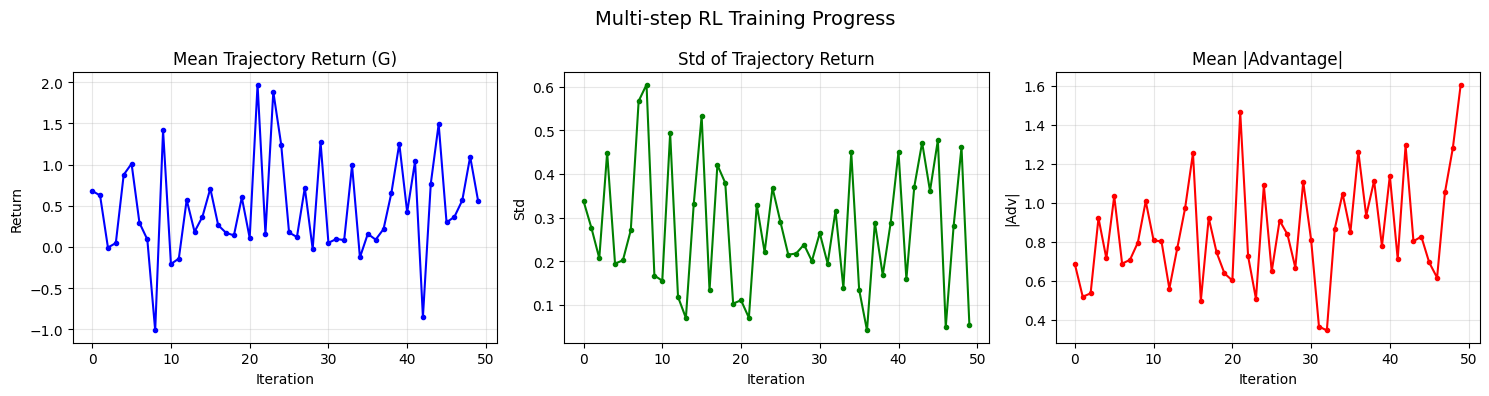

Saved reward decomposition plot to: output/training_plots/reward_decomposition_nonsubprocess_stage3_iters50_prompts163415_20260514_141526_907909.png


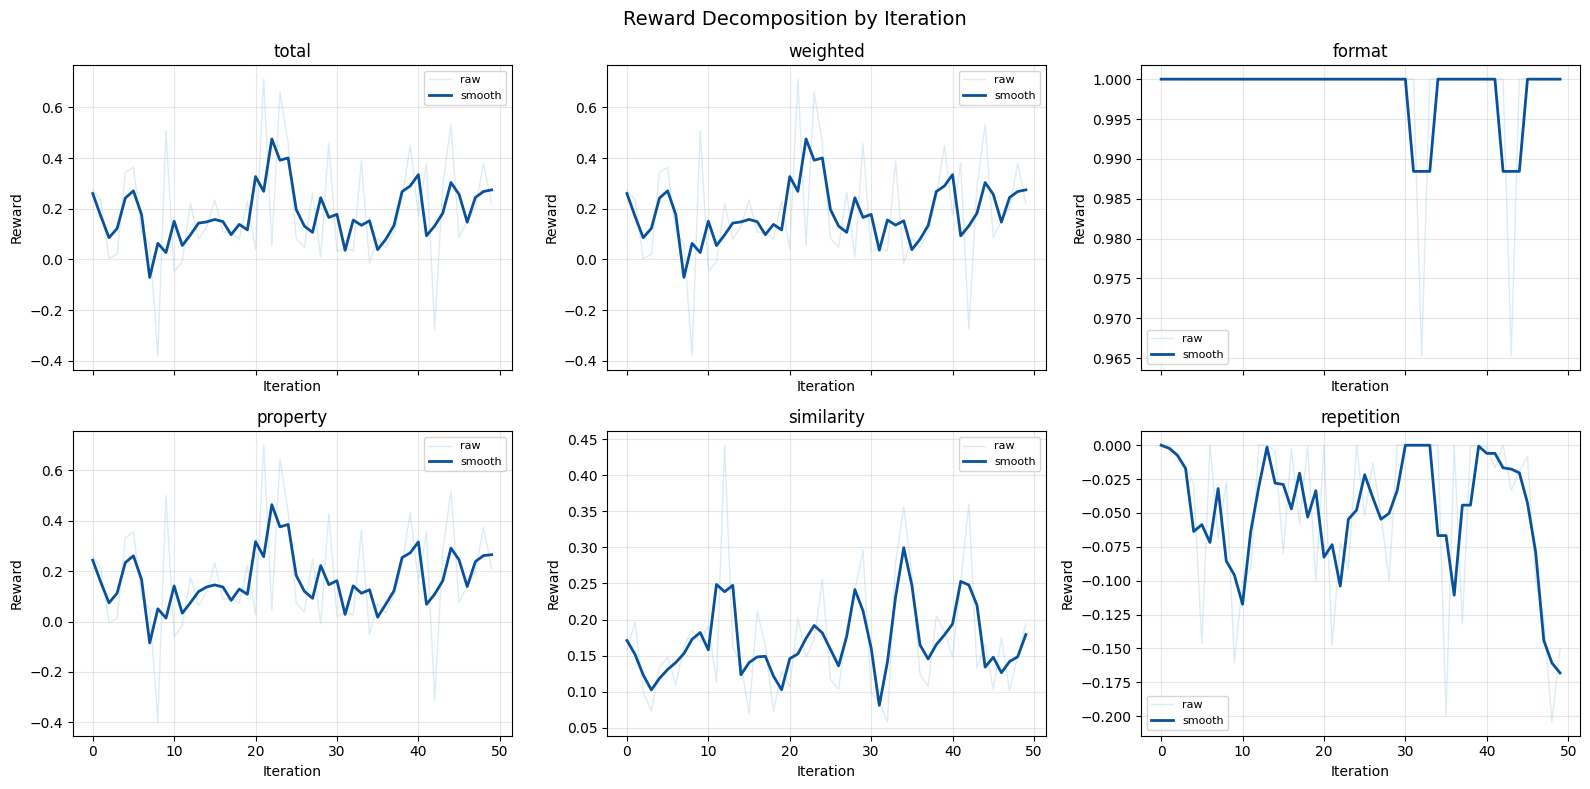

Saved NTE plot to: output/training_plots/nte_errors_nonsubprocess_stage3_iters50_prompts163415_20260514_141526_907909.png


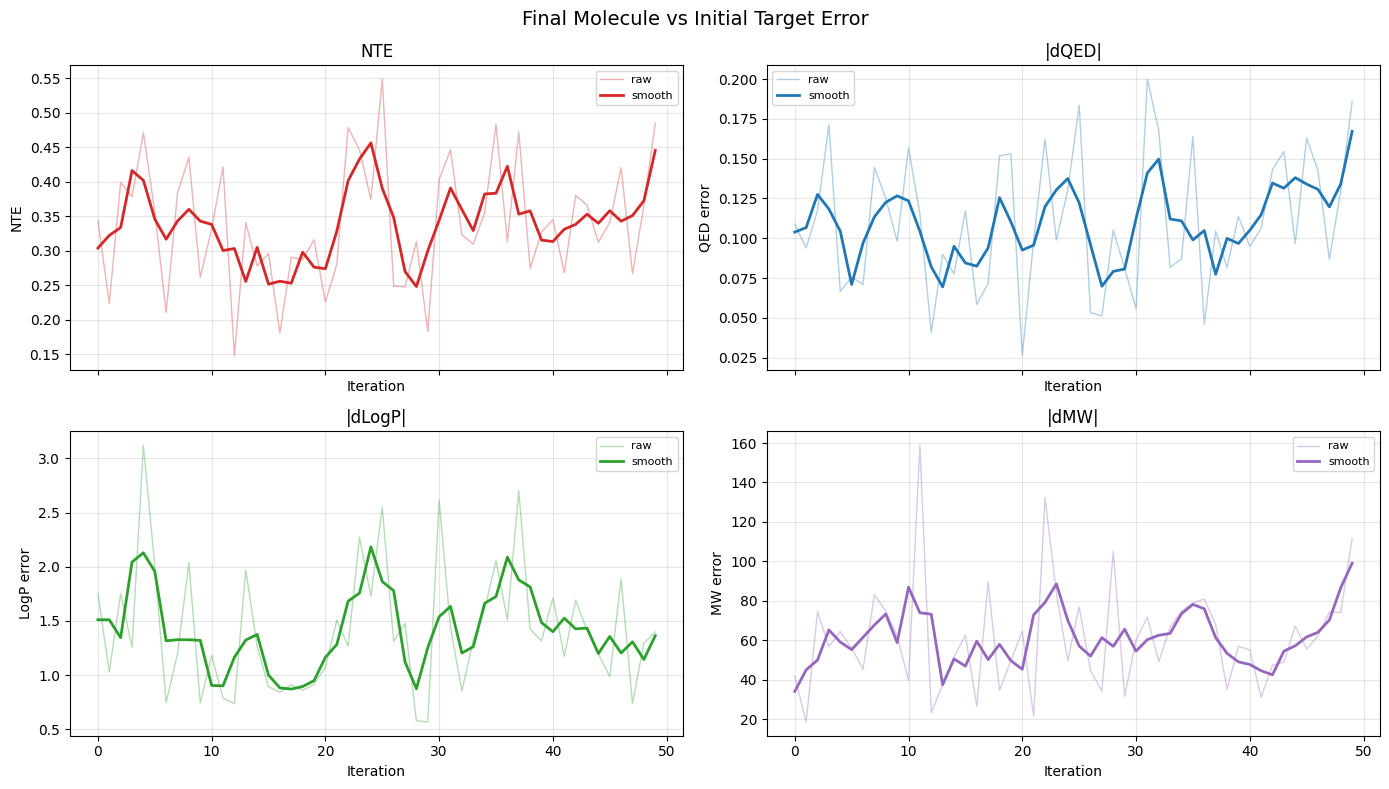

Saved metrics bundle to: out/training_metrics/multiturn_nonsubprocess_stage3_iters50_prompts163415_20260514_141526_907909


In [21]:
from datetime import datetime
from pathlib import Path
from matplotlib import pyplot as plt

if "all_metrics" not in globals():
    raise ValueError(
        "all_metrics is undefined. Run: all_metrics = run_multistep_rl_training_fixed(...) first."
    )
if not all_metrics:
    raise ValueError("all_metrics is empty. Please run training first.")

def _smooth_series(values, window: int = 3):
    """Simple moving average with edge padding for short metric series."""
    arr = np.asarray(values, dtype=np.float64)
    if arr.size == 0 or window <= 1 or arr.size < window:
        return arr.tolist()
    kernel = np.ones(window, dtype=np.float64) / window
    pad_left = window // 2
    pad_right = window - 1 - pad_left
    padded = np.pad(arr, (pad_left, pad_right), mode="edge")
    smooth = np.convolve(padded, kernel, mode="valid")
    return smooth.tolist()

iters = [m["iteration"] for m in all_metrics]
first = all_metrics[0]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
save_dir = Path("output/training_plots")
save_dir.mkdir(parents=True, exist_ok=True)

def _auto_run_tag() -> str:
    explicit = globals().get("RUN_TAG")
    if explicit:
        return str(explicit)
    parts = []
    experiment_name = globals().get("RUN_EXPERIMENT")
    if experiment_name:
        parts.append(str(experiment_name))
    parts.append(f"iters{len(all_metrics)}")
    if 'raw_data' in globals():
        parts.append(f"prompts{len(raw_data)}")
    parts.append(datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    return "_".join(parts)

run_tag = _auto_run_tag()

def _metric_series(key: str):
    values = []
    for metric in all_metrics:
        value = metric.get(key, np.nan)
        values.append(float(value) if value is not None else np.nan)
    return values

def _assert_fresh_output_path(path: Path, *, kind: str) -> None:
    if path.exists():
        raise FileExistsError(
            f"Refusing to overwrite existing {kind}: {path}. Change run_tag before saving."
        )

if "mean_reward" in first:
    # Mode A metrics
    mean_reward = [m.get("mean_reward", 0.0) for m in all_metrics]
    mean_edit = [m.get("mean_edit", 0.0) for m in all_metrics]
    mean_outcome = [m.get("mean_outcome", 0.0) for m in all_metrics]

    axes[0].plot(iters, mean_reward, "b-o", markersize=3)
    axes[0].set_title("Mean Reward")
    axes[0].set_ylabel("Reward")

    axes[1].plot(iters, mean_edit, "g-o", markersize=3)
    axes[1].set_title("Mean EDIT Reward")
    axes[1].set_ylabel("Reward")

    axes[2].plot(iters, mean_outcome, "r-o", markersize=3)
    axes[2].set_title("Mean Outcome Reward")
    axes[2].set_ylabel("Reward")

    reward_component_keys = []

elif "mean_G" in first:
    # Mode B metrics
    mean_G = [m.get("mean_G", 0.0) for m in all_metrics]
    std_G = [m.get("std_G", 0.0) for m in all_metrics]

    # Under group-normalized GRPO, mean_adv is expected near 0.
    # Prefer |adv| and std_adv to observe signal strength.
    if "mean_abs_adv" in first:
        adv_signal = [m.get("mean_abs_adv", 0.0) for m in all_metrics]
        adv_title = "Mean |Advantage|"
        adv_ylabel = "|Adv|"
    else:
        adv_signal = [m.get("mean_adv", 0.0) for m in all_metrics]
        adv_title = "Mean Advantage"
        adv_ylabel = "Advantage"

    axes[0].plot(iters, mean_G, "b-o", markersize=3)
    axes[0].set_title("Mean Trajectory Return (G)")
    axes[0].set_ylabel("Return")

    axes[1].plot(iters, std_G, "g-o", markersize=3)
    axes[1].set_title("Std of Trajectory Return")
    axes[1].set_ylabel("Std")

    axes[2].plot(iters, adv_signal, "r-o", markersize=3)
    axes[2].set_title(adv_title)
    axes[2].set_ylabel(adv_ylabel)

    reward_component_keys = [
        ("mean_reward_total", "total"),
        ("mean_reward_weighted", "weighted"),
        ("mean_reward_format", "format"),
        ("mean_reward_property", "property"),
        ("mean_reward_similarity", "similarity"),
        ("mean_reward_repetition", "repetition"),
    ]

else:
    raise ValueError("Unknown metric schema in all_metrics.")

for ax in axes:
    ax.set_xlabel("Iteration")
    ax.grid(True, alpha=0.3)

plt.suptitle("Multi-step RL Training Progress", fontsize=14)
plt.tight_layout()
main_plot_path = save_dir / f"training_progress_{run_tag}.png"
_assert_fresh_output_path(main_plot_path, kind="training plot")
fig.savefig(main_plot_path, dpi=200, bbox_inches="tight")
print(f"Saved main training plot to: {main_plot_path}")
plt.show()

# Extra figure: reward decomposition curves for Mode B.
if reward_component_keys:
    fig2, axes2 = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
    axes2 = axes2.flatten()

    for ax, (metric_key, title) in zip(axes2, reward_component_keys):
        values = [m.get(metric_key, 0.0) for m in all_metrics]
        smooth_values = _smooth_series(values, window=3)
        ax.plot(iters, values, color="#9ecae1", linewidth=1.0, alpha=0.35, label="raw")
        ax.plot(iters, smooth_values, color="#08519c", linewidth=2.0, label="smooth")
        ax.set_title(title)
        ax.set_xlabel("Iteration")
        ax.set_ylabel("Reward")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best", fontsize=8)

    plt.suptitle("Reward Decomposition by Iteration", fontsize=14)
    plt.tight_layout()
    reward_plot_path = save_dir / f"reward_decomposition_{run_tag}.png"
    _assert_fresh_output_path(reward_plot_path, kind="reward decomposition plot")
    fig2.savefig(reward_plot_path, dpi=200, bbox_inches="tight")
    print(f"Saved reward decomposition plot to: {reward_plot_path}")
    plt.show()

# Extra figure: NTE and per-property final target errors.
if "mean_nte" in first:
    fig3, axes3 = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    axes3 = axes3.flatten()
    nte_plot_specs = [
        ("mean_nte", "NTE", "NTE", "#d62728"),
        ("mean_final_qed_error", "|dQED|", "QED error", "#1f77b4"),
        ("mean_final_logp_error", "|dLogP|", "LogP error", "#2ca02c"),
        ("mean_final_mw_error", "|dMW|", "MW error", "#9467bd"),
    ]
    for ax, (metric_key, title, ylabel, color) in zip(axes3, nte_plot_specs):
        values = _metric_series(metric_key)
        smooth_values = _smooth_series(values, window=3)
        ax.plot(iters, values, color=color, linewidth=1.0, alpha=0.35, label="raw")
        ax.plot(iters, smooth_values, color=color, linewidth=2.0, label="smooth")
        ax.set_title(title)
        ax.set_xlabel("Iteration")
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best", fontsize=8)

    plt.suptitle("Final Molecule vs Initial Target Error", fontsize=14)
    plt.tight_layout()
    nte_plot_path = save_dir / f"nte_errors_{run_tag}.png"
    _assert_fresh_output_path(nte_plot_path, kind="NTE plot")
    fig3.savefig(nte_plot_path, dpi=200, bbox_inches="tight")
    print(f"Saved NTE plot to: {nte_plot_path}")
    plt.show()

import importlib
import training_metrics_io as _training_metrics_io

_training_metrics_io = importlib.reload(_training_metrics_io)

metrics_artifacts = _training_metrics_io.save_training_metrics_from_globals(
    globals(),
    output_dir="out/training_metrics",
    run_name=f"multiturn_{run_tag}",
    allow_overwrite=False,
)
print(f"Saved metrics bundle to: {metrics_artifacts['run_dir']}")

## 9. Evaluate the Final Model

In [ ]:
sft_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)
sft_training_client.load_state("tinker://74e5f0bc-93c9-5df1-9570-5ed0910d9daa:train:0/weights/sft-final")
sft_sampling_client = sft_training_client.save_weights_and_get_sampling_client(name="sft-sampler.weekend")
grpo_training_client = service_client.create_lora_training_client(
    base_model=BASE_MODEL,
    rank=LORA_RANK,
)
grpo_training_client.load_state("tinker://eb393fba-89e6-5005-b2f2-3df09d6142c3:train:0/weights/grpo-final.weekend")
grpo_sampling_client = grpo_training_client.save_weights_and_get_sampling_client(name="grpo-sampler.weekend")

In [ ]:
# Save the final GRPO checkpoint
grpo_save_result = grpo_training_client.save_state(name="MultistepRL-grpo-final.weekend.Qwen8B").result()
grpo_checkpoint_path = grpo_save_result.path
print(f"GRPO checkpoint saved at: {grpo_checkpoint_path}")

## 10. Download the Trained Weights

You can download the LoRA adapter weights to use with your own inference setup (e.g., vLLM, SGLang, or HuggingFace).

In [2]:
# Download the GRPO model weights
# The downloaded weights are a LoRA adapter that can be loaded
# with HuggingFace PEFT or merged into the base model.

rest_client = service_client.create_rest_client()

# List available checkpoints
future = rest_client.list_checkpoints("run_id").result()  # Uncomment to see all checkpoints
# Download to a local directory
# Uncomment and run when ready:
# rest_client.download_checkpoint(grpo_checkpoint_path, output_dir="./grpo-weights")
# print("Weights downloaded to ./grpo-weights/")

# print(f"GRPO checkpoint path: {grpo_checkpoint_path}")
# print("Uncomment the download line above when you're ready to export.")

NotFoundError: Error code: 404 - {'detail': 'Model not found.'}

---

## Summary & Next Steps

In this notebook, we:

1. **Loaded** the `Alan123/homo-lumo-grpo` dataset from HuggingFace
2. **SFT-trained** a Qwen3 model to learn the chemistry Q&A format using `cross_entropy` loss
3. **GRPO-trained** the model using RL with a custom reward function and `ppo` loss
4. **Compared** SFT vs GRPO predictions side by side

### Tips for better results:

- **More SFT steps** — if your dataset is large, train for more steps or multiple epochs
- **Tune the reward function** — the reward function is the most important part of GRPO. Make it reflect what you actually care about.
- **Try different loss functions** — Tinker supports `importance_sampling`, `ppo`, `cispo`, and `dro`. See the [Loss Functions docs](https://tinker-docs.thinkingmachines.ai/losses)
- **Increase samples per prompt** — more completions per prompt = better advantage estimates
- **Use a larger model** — `Qwen/Qwen3-30B-A3B` (MoE) is very cost-effective and much more capable
- **Use the Tinker Cookbook** — the cookbook has optimized training loops with async operations, logging, and eval. See [rl/train.py](https://github.com/thinking-machines-lab/tinker-cookbook/blob/main/tinker_cookbook/rl/train.py)

### Key Tinker resources:
- [Tinker API Docs](https://tinker-docs.thinkingmachines.ai/)
- [Supervised Learning Guide](https://tinker-docs.thinkingmachines.ai/supervised-learning/sl-basic)
- [RL Training Guide](https://tinker-docs.thinkingmachines.ai/rl/rl-basic)
- [Model Lineup](https://tinker-docs.thinkingmachines.ai/model-lineup)
- [Tinker Cookbook (GitHub)](https://github.com/thinking-machines-lab/tinker-cookbook)

In [ ]:
# 诊断（精简版）：查看指定 prompt 的逐轮原始输出与环境反馈（无四步）
prompt_idx = 14584
max_turns = 3

example = raw_data[int(prompt_idx)]
prompt_text = str(example[PROMPT_COL])
ground_truth = str(example[ANSWER_COL])

def _replace_prompt_smiles(base_prompt: str, current_smiles: str) -> str:
    """
    Replace current molecule and refresh per-property target deltas.

    - Refresh the fragments clause from the latest molecule for later turns.
    - Keep absolute target values fixed and recompute <QED>/<LogP>/<MW>
      deltas relative to the new current molecule.
    """
    new_prompt = re.sub(
        r"<SMILES>.*?</SMILES>",
        lambda _m: f"<SMILES>{current_smiles}</SMILES>",
        base_prompt,
        count=1,
        flags=re.DOTALL,
    )

    # Rebuild fragment hints from the latest molecule for the next turn.
    fragment_fn = globals().get("get_clean_fragments")
    if callable(fragment_fn):
        try:
            fragment_list = fragment_fn(current_smiles)
        except Exception:
            fragment_list = []
    else:
        fragment_list = []

    if not fragment_list:
        fragment_list = [current_smiles]

    fragment_repr = repr(fragment_list)
    new_prompt = re.sub(
        r"(<SMILES>.*?</SMILES>)(?:,\s*which is composed of fragments\s+.*?\.)?",
        lambda m: f"{m.group(1)}, which is composed of fragments {fragment_repr}.",
        new_prompt,
        count=1,
        flags=re.DOTALL,
    )

    mol_old = _mol_from_prompt(base_prompt)
    mol_new = Chem.MolFromSmiles(current_smiles)
    if mol_old is None or mol_new is None:
        return new_prompt

    prop_specs = [
        ("QED", QED.qed, True),
        ("LogP", Crippen.MolLogP, False),
        ("MW", Descriptors.ExactMolWt, False),
    ]

    for prop, fn, is_qed in prop_specs:
        m = re.search(rf"<{prop}>(-?\d*\.?\d+)</{prop}>\s*(higher|lower)", new_prompt)
        if not m:
            continue

        old_delta = float(m.group(1))
        old_dir = m.group(2).lower()
        old_base = float(fn(mol_old))
        target_abs = old_base + (old_delta if old_dir == "higher" else -old_delta)
        if is_qed:
            target_abs = max(0.01, min(0.99, target_abs))

        new_base = float(fn(mol_new))
        new_dir = "higher" if target_abs >= new_base else "lower"
        new_delta = abs(target_abs - new_base)

        new_prompt = re.sub(
            rf"<{prop}>-?\d*\.?\d+</{prop}>\s*(higher|lower)",
            f"<{prop}>{new_delta:.3f}</{prop}> {new_dir}",
            new_prompt,
            count=1,
        )

    return new_prompt

def _compact_env_feedback(feedback_text: str) -> str:
    """Keep only headline + final summary to avoid repeating target lines."""
    if not feedback_text:
        return ""
    lines = [ln.strip() for ln in feedback_text.splitlines() if ln.strip()]
    if not lines:
        return feedback_text
    if lines[0].startswith("Environment feedback:"):
        if len(lines) == 1:
            return lines[0]
        tail = lines[-1]
        if tail == lines[0]:
            return lines[0]
        return lines[0] + "\n" + tail
    return feedback_text

mol_in = _mol_from_prompt(prompt_text)
if mol_in is not None:
    qed_val = QED.qed(mol_in)
    logp_val = Crippen.MolLogP(mol_in)
    mw_val = Descriptors.ExactMolWt(mol_in)
else:
    qed_val = logp_val = mw_val = float("nan")

print("=" * 100)
print(f"Prompt idx={prompt_idx}")
print(prompt_text)
print(ground_truth)
print(f"Input molecule: QED={qed_val:.4f} logP={logp_val:.4f} MW={mw_val:.2f}")
print("=" * 100)

current_prompt_for_generation = prompt_text
prev_env_feedback = ""
prev_guidance = ""

for turn_idx in range(max_turns):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT_RL},
        {"role": "user", "content": current_prompt_for_generation},
    ]
    if turn_idx > 0 and (prev_env_feedback or prev_guidance):
        feedback_parts = [
            "Environment feedback from your previous attempt:",
            prev_env_feedback,
            "",
            "Target-gap priorities from previous turn (must address first):",
            prev_guidance,
            "",
            "Interpretation rules (must follow):",
            "- If a property says 'need ... more increase/decrease', move in that direction.",
            "- If a property says 'overshot by ...', reverse slightly toward target.",
            "- Keep already-met properties near target while fixing unmet ones.",
            "",
            "Use the current molecule shown in the prompt above as the only edit base.",
            "Do not restart from the original molecule.",
        ]
        messages.append(
            {
                "role": "user",
                "content": "\n".join(feedback_parts).strip(),
            }
        )

    print(f"\n[TURN {turn_idx}] messages sent to model:")
    for msg_i, msg in enumerate(messages):
        print(f"--- message[{msg_i}] role={msg.get('role')} ---")
        print(msg.get("content", ""))

    prompt_input = renderer.build_generation_prompt(messages)
    result = grpo_sampling_client.sample(
        prompt=prompt_input,
        sampling_params=types.SamplingParams(
            max_tokens=256,
            temperature=0.7,
            stop=renderer.get_stop_sequences(),
        ),
        num_samples=1,
    ).result()

    seq = result.sequences[0]
    completion_text = tokenizer.decode(
        seq.tokens,
        skip_special_tokens=True,
    )
    completion_text = _normalize_completion_text(completion_text)

    pred_smiles = extract_smiles(completion_text)
    reward = compute_reward(completion_text, current_prompt_for_generation, ground_truth)
    env_feedback, mol_out, all_met = _run_env(completion_text, current_prompt_for_generation)

    turn_mol_in = _mol_from_prompt(current_prompt_for_generation)
    if turn_mol_in is not None and mol_out is not None:
        unmet_props, progress_lines = _target_progress_lines(
            turn_mol_in,
            mol_out,
            current_prompt_for_generation,
        )
        unmet_text = ", ".join(unmet_props) if unmet_props else "none"
        if progress_lines:
            progress_block = "\n".join([f"- {line}" for line in progress_lines])
        else:
            progress_block = "- target-gap details unavailable."
        prev_guidance = (
            f"all_met={all_met}; unmet_properties={unmet_text}.\n"
            f"{progress_block}"
        )
    else:
        prev_guidance = (
            "all_met=False; unmet_properties=unknown.\n"
            "- target-gap details unavailable. First generate a valid molecule in <SMILES>...</SMILES>."
        )

    if pred_smiles and mol_out is not None:
        current_prompt_for_generation = _replace_prompt_smiles(current_prompt_for_generation, pred_smiles)
    prev_env_feedback = _compact_env_feedback(env_feedback)

    is_last = (turn_idx == max_turns - 1) or all_met
    if is_last:
        break

Prompt idx=14584
Given the intermediate molecule SMILES <SMILES>CC[C@H]1CC[C@](O)([C@]2(C#N)CCc3ccccc32)C1</SMILES>, which is composed of fragments ['CC', '[C@H]1CC[C@](O)([C@]2(C#N)CCc3ccccc32)C1']. Propose a single replace, add or remove step on fragment level that makes the new molecule's QED <QED>0.079</QED> lower, LogP <LogP>0.350</LogP> lower, and Molecular Weight <MW>31.076</MW> higher.
Replace [C@H]1CC[C@](O)([C@]2(C#N)CCc3ccccc32)C1 with [C@H]1CCC(=O)[C@H]([C@@H]2CCC[C@H](S(C)(=O)=O)C2)C1 to form <SMILES>CC[C@H]1CCC(=O)[C@H]([C@@H]2CCC[C@H](S(C)(=O)=O)C2)C1</SMILES>.
Input molecule: QED=0.8805 logP=3.3354 MW=255.16

[TURN 0] messages sent to model:
--- message[0] role=system ---

You are a helpful chemistry assistant for multi-turn molecule optimization.

Rules:
1) Output exactly one edit action sentence in one of these formats:
   - Replace <old_fragment> with <new_fragment> to form <SMILES>new_smiles_here</SMILES>.
   - Add <fragment> to form <SMILES>new_smiles_here</SMILES>

In [20]:
from pathlib import Path
import json
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import training_metrics_io as _tmio

_tmio = importlib.reload(_tmio)

ROOT = Path("/home/weekend/workspace/AI4Materials")
AB_DIR = ROOT / "out/training_metrics/stage2_compare_ab_20260502"
VS1_DIR = ROOT / "out/training_metrics/stage2_compare_vs_stage1_20260502"
AB_DIR.mkdir(parents=True, exist_ok=True)
VS1_DIR.mkdir(parents=True, exist_ok=True)

STAGE1_BASELINE_LAST20 = VS1_DIR / "stage1_baseline_last20_summary.csv"

CORE_METRICS = [
    "mean_G",
    "mean_nte",
    "mean_reward_total",
    "mean_reward_format",
    "mean_reward_property",
    "mean_reward_similarity",
    "mean_reward_repetition",
]

def set_runtime_reward_weights(format_w, property_w, similarity_w, repetition_w):
    BASE_REWARD_WEIGHTS.clear()
    BASE_REWARD_WEIGHTS.update(
        {
            "format": float(format_w),
            "property": float(property_w),
            "similarity": float(similarity_w),
            "repetition": float(repetition_w),
        }
    )
    print("Runtime BASE_REWARD_WEIGHTS =", BASE_REWARD_WEIGHTS)

def run_stage2_branch(
    branch_name,
    *,
    format_w,
    property_w,
    similarity_w,
    repetition_w,
    use_repetition_reward,
    num_iterations=25,
):
    set_runtime_reward_weights(format_w, property_w, similarity_w, repetition_w)

    globals()["RUN_EXPERIMENT"] = branch_name
    globals()["RUN_TAG"] = (
        f"{branch_name}_iter400_lr1e6_refresh2_"
        f"{'rep' if use_repetition_reward else 'norep'}_{num_iterations}"
    )

    cfg = dict(
        num_iterations=num_iterations,
        prompts_per_iter=4,
        learning_rate=1e-6,
        trajectories_per_prompt=4,
        max_turns=3,
        gamma=0.85,
        ema_alpha=0.05,
        rng_seed=42,
        debug_adv=False,
        debug_prompts_per_iter=0,
        debug_iterations=0,
        keep_skipped_metrics=True,
        refresh_sampling_every=2,
        use_repetition_reward=use_repetition_reward,
    )

    metrics = run_multistep_rl_training_fixed(
        raw_data=raw_data,
        renderer=renderer,
        training_client=grpo_training_client,
        tokenizer=tokenizer,
        **cfg,
    )
    globals()["all_metrics"] = metrics

    artifacts = _tmio.save_training_metrics_from_globals(
        globals(),
        output_dir=ROOT / "out/training_metrics",
        run_name=f"multiturn_{RUN_TAG}",
        allow_overwrite=False,
    )
    print(json.dumps(artifacts, ensure_ascii=False, indent=2))
    return metrics, artifacts

def summarize_windows(metrics_csv, label):
    df = pd.read_csv(metrics_csv)
    rows = []
    for window in (10, 20):
        sub = df.tail(window)
        for key in CORE_METRICS:
            if key not in sub.columns:
                continue
            rows.append(
                {
                    "label": label,
                    "window": f"last{window}",
                    "metric": key,
                    "mean": float(sub[key].mean()),
                    "std": float(sub[key].std()),
                    "min": float(sub[key].min()),
                    "max": float(sub[key].max()),
                }
            )
    return pd.DataFrame(rows)

def plot_branch_compare(csv_a, label_a, csv_b, label_b, out_png):
    specs = [
        ("mean_G", "Mean G"),
        ("mean_reward_total", "Total Reward"),
        ("mean_reward_property", "Property Reward"),
        ("mean_reward_similarity", "Similarity Reward"),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
    axes = axes.ravel()

    for ax, (key, title) in zip(axes, specs):
        for csv_path, label, color in [
            (csv_a, label_a, "#1f77b4"),
            (csv_b, label_b, "#d62728"),
        ]:
            df = pd.read_csv(csv_path)
            x = df["iteration"].to_numpy()
            y = df[key].to_numpy()
            y_smooth = pd.Series(y).rolling(5, center=True, min_periods=1).mean().to_numpy()
            ax.plot(x, y, color=color, alpha=0.25)
            ax.plot(x, y_smooth, color=color, linewidth=2, label=label)
        ax.set_title(title)
        ax.grid(alpha=0.25)
        ax.legend()

    fig.suptitle("Branch from iter400 checkpoint", fontsize=14)
    fig.tight_layout()
    fig.savefig(out_png, dpi=200, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved: {out_png}")


In [21]:
metrics_A, artifacts_A = run_stage2_branch(
    "stage2A",
    format_w=0.20,
    property_w=0.60,
    similarity_w=0.20,
    repetition_w=0.05,
    use_repetition_reward=False,
    num_iterations=25,
)


Runtime BASE_REWARD_WEIGHTS = {'format': 0.2, 'property': 0.6, 'similarity': 0.2, 'repetition': 0.05}
启动多轮 RL 训练
repetition reward enabled=False (effective_weight=0.00)
Iter |   Mean G |   std_G |   |adv| | std_adv |  +adv% |  #data |   t(s)
------------------------------------------------------------------------
   0 |  -1.7042 |  0.5039 |  0.6932 |  0.7500 |  31.2% |     48 |   45.1
      rewards | total=-0.665 (weighted=-0.665) | format=+0.792 | property=-1.379 | similarity=+0.188 | repetition=-0.429
   1 |  -1.4324 |  0.2500 |  1.3600 |  0.5000 |  56.2% |     48 |   36.1
      rewards | total=-0.555 (weighted=-0.555) | format=+1.000 | property=-1.322 | similarity=+0.193 | repetition=-0.602
   2 |  -2.4460 |  0.0031 |  0.8113 |  0.2500 |   6.2% |     48 |   38.1
      rewards | total=-0.949 (weighted=-0.949) | format=+1.000 | property=-1.967 | similarity=+0.156 | repetition=-0.724
   3 |  -1.5350 |  0.0041 |  1.4871 |  0.5000 |  37.5% |     48 |   32.0
      rewards | total=-0.596 (

In [24]:
metrics_B, artifacts_B = run_stage2_branch(
    "stage2B",
    format_w=0.10,
    property_w=0.60,
    similarity_w=0.20,
    repetition_w=0.10,
    use_repetition_reward=True,
    num_iterations=25,
)


Runtime BASE_REWARD_WEIGHTS = {'format': 0.1, 'property': 0.6, 'similarity': 0.2, 'repetition': 0.1}
启动多轮 RL 训练
repetition reward enabled=True (effective_weight=0.10)
Iter |   Mean G |   std_G |   |adv| | std_adv |  +adv% |  #data |   t(s)
------------------------------------------------------------------------
   0 |  -1.7510 |  0.6407 |  0.8779 |  1.0000 |  50.0% |     48 |   41.5
      rewards | total=-0.671 (weighted=-0.671) | format=+0.896 | property=-1.212 | similarity=+0.176 | repetition=-0.438
   1 |  -2.4340 |  0.6467 |  0.8573 |  1.0000 |  56.2% |     48 |   38.4
      rewards | total=-0.933 (weighted=-0.933) | format=+0.896 | property=-1.624 | similarity=+0.176 | repetition=-0.583
   2 |  -3.0173 |  0.2753 |  0.8856 |  1.0000 |  56.2% |     48 |   37.4
      rewards | total=-1.163 (weighted=-1.163) | format=+0.896 | property=-1.979 | similarity=+0.152 | repetition=-0.706
   3 |  -2.0265 |  0.1078 |  0.8858 |  1.0000 |  56.2% |     48 |   30.2
      rewards | total=-0.792 (we

# 诊断

In [17]:
import importlib
import reward_saturation_diagnostic as rsd

rsd = importlib.reload(rsd)

records, summary, artifacts = rsd.run_reward_saturation_diagnostic(
    globals(),
    checkpoint="800",          # 也可以改成 "700"
    num_prompts=32,
    samples_per_prompt=12,
    temperature=0.9,
    max_tokens=128,
)


[rewarddiag] prompt 1/32 idx=550 done
[rewarddiag] prompt 2/32 idx=749 done
[rewarddiag] prompt 3/32 idx=1950 done
[rewarddiag] prompt 4/32 idx=3770 done
[rewarddiag] prompt 5/32 idx=4002 done
[rewarddiag] prompt 6/32 idx=4213 done
[rewarddiag] prompt 7/32 idx=14681 done
[rewarddiag] prompt 8/32 idx=15469 done
[rewarddiag] prompt 9/32 idx=19260 done
[rewarddiag] prompt 10/32 idx=29811 done
[rewarddiag] prompt 11/32 idx=33582 done
[rewarddiag] prompt 12/32 idx=50638 done
[rewarddiag] prompt 13/32 idx=56841 done
[rewarddiag] prompt 14/32 idx=72337 done
[rewarddiag] prompt 15/32 idx=87754 done
[rewarddiag] prompt 16/32 idx=89858 done
[rewarddiag] prompt 17/32 idx=92517 done
[rewarddiag] prompt 18/32 idx=96868 done
[rewarddiag] prompt 19/32 idx=97365 done
[rewarddiag] prompt 20/32 idx=98719 done
[rewarddiag] prompt 21/32 idx=102897 done
[rewarddiag] prompt 22/32 idx=117802 done
[rewarddiag] prompt 23/32 idx=119472 done
[rewarddiag] prompt 24/32 idx=122706 done
[rewarddiag] prompt 25/32 idx